#1. Setup the mixed-precision experiment

In [1]:
# ============================================================
# NOTEBOOK 05 — Mixed-Precision KV Cache
# CELL 1 — Setup
# ============================================================

!pip -q install -U transformers accelerate safetensors datasets

import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import math
import random

from tqdm.auto import tqdm
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    DynamicCache
)
from datasets import load_dataset


# --------------------------------------------------
# Model configuration
# --------------------------------------------------

MODEL_ID = "Qwen/Qwen2.5-1.5B"
DTYPE = torch.float16

PAGE_SIZE = 16
EVAL_TOKENS = 2048

# Fractions of pages that will use INT4.
# The remaining quantized pages use INT8.
INT4_FRACTIONS = [
    0.00,
    0.10,
    0.25,
    0.50,
    0.75,
    1.00
]

RANDOM_SEED = 42


# --------------------------------------------------
# GPU
# --------------------------------------------------

print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU runtime required.")

gpu = torch.cuda.get_device_properties(0)

print("GPU:", gpu.name)
print(
    f"VRAM: "
    f"{gpu.total_memory / 1024**3:.2f} GiB"
)


# --------------------------------------------------
# Load model
# --------------------------------------------------

print("\nLoading:", MODEL_ID)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
    device_map={"": 0},
    low_cpu_mem_usage=True,
    attn_implementation="sdpa",
)

model.eval()


# --------------------------------------------------
# Architecture
# --------------------------------------------------

config = model.config

NUM_LAYERS = config.num_hidden_layers
NUM_ATTENTION_HEADS = config.num_attention_heads

NUM_KV_HEADS = getattr(
    config,
    "num_key_value_heads",
    NUM_ATTENTION_HEADS
)

HEAD_DIM = getattr(
    config,
    "head_dim",
    config.hidden_size // NUM_ATTENTION_HEADS
)


# --------------------------------------------------
# WikiText-2
# --------------------------------------------------

test_dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1",
    split="test"
)

test_text = "\n\n".join(
    test_dataset["text"]
)

encodings = tokenizer(
    test_text,
    return_tensors="pt",
    add_special_tokens=False
)

all_test_ids = encodings.input_ids

eval_ids = all_test_ids[
    :, :EVAL_TOKENS
].to(model.device)


# --------------------------------------------------
# Page configuration
# --------------------------------------------------

NUM_PAGES = math.ceil(
    EVAL_TOKENS / PAGE_SIZE
)


# --------------------------------------------------
# Print experiment configuration
# --------------------------------------------------

print("\nMixed-Precision Experiment")
print("--------------------------")

print("Evaluation tokens:", EVAL_TOKENS)
print("Page size:", PAGE_SIZE)
print("Number of pages:", NUM_PAGES)

print("\nModel")
print("Layers:", NUM_LAYERS)
print("Attention heads:", NUM_ATTENTION_HEADS)
print("KV heads:", NUM_KV_HEADS)
print("Head dimension:", HEAD_DIM)

print("\nINT4 fractions:")
for fraction in INT4_FRACTIONS:
    print(
        f"  {fraction:>4.0%} INT4 "
        f"/ {1-fraction:>4.0%} INT8"
    )

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 83.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 19.3 MB/s eta 0:00:00
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GiB

Loading: Qwen/Qwen2.5-1.5B


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors



Mixed-Precision Experiment
--------------------------
Evaluation tokens: 2048
Page size: 16
Number of pages: 128

Model
Layers: 28
Attention heads: 12
KV heads: 2
Head dimension: 128

INT4 fractions:
    0% INT4 / 100% INT8
   10% INT4 /  90% INT8
   25% INT4 /  75% INT8
   50% INT4 /  50% INT8
   75% INT4 /  25% INT8
  100% INT4 /   0% INT8


#2. Mixed-precision quantization helpers

In [2]:
# ============================================================
# CELL 2 — Mixed-Precision Quantization Helpers
# ============================================================


# --------------------------------------------------
# Symmetric uniform quantization
# --------------------------------------------------

def symmetric_quantize(tensor, num_bits):
    """
    Symmetric per-tensor quantization.

    num_bits:
        8 -> integer range [-127, 127]
        4 -> integer range [-7, 7]
    """

    if num_bits not in [4, 8]:
        raise ValueError("num_bits must be 4 or 8")

    qmax = (2 ** (num_bits - 1)) - 1
    qmin = -qmax

    x = tensor.float()

    max_abs = x.abs().max()

    if max_abs.item() == 0:

        scale = torch.tensor(
            1.0,
            device=tensor.device,
            dtype=torch.float32
        )

    else:

        scale = max_abs / qmax


    q = torch.round(
        x / scale
    )

    q = torch.clamp(
        q,
        qmin,
        qmax
    )

    # INT4 is simulated using an int8 container.
    # Only values [-7, 7] are used.
    q = q.to(torch.int8)

    return q, scale


# --------------------------------------------------
# Dequantization
# --------------------------------------------------

def symmetric_dequantize(
    q_tensor,
    scale,
    dtype=torch.float16
):

    return (
        q_tensor.float() * scale
    ).to(dtype)


# --------------------------------------------------
# Quantize one completed logical page
#
# Every layer gets independent K and V scales.
# --------------------------------------------------

@torch.inference_mode()
def quantize_completed_page_inplace(
    cache,
    start_token,
    end_token,
    precision
):
    """
    Replace one completed logical KV page with its
    quantized/dequantized approximation.

    precision:
        "INT8"
        "INT4"

    The page is quantized independently for:
        every transformer layer
        Key and Value separately
    """

    if precision == "INT8":
        num_bits = 8

    elif precision == "INT4":
        num_bits = 4

    else:
        raise ValueError(
            "precision must be 'INT8' or 'INT4'"
        )


    page_scales = []


    for layer_idx, layer in enumerate(cache.layers):

        # ------------------------------------------
        # Extract this token page
        # ------------------------------------------

        key_page = layer.keys[
            :, :, start_token:end_token, :
        ]

        value_page = layer.values[
            :, :, start_token:end_token, :
        ]


        # ------------------------------------------
        # Independent K / V quantization
        # ------------------------------------------

        q_key, key_scale = symmetric_quantize(
            key_page,
            num_bits
        )

        q_value, value_scale = symmetric_quantize(
            value_page,
            num_bits
        )


        # ------------------------------------------
        # Dequantize for normal attention reuse
        # ------------------------------------------

        dq_key = symmetric_dequantize(
            q_key,
            key_scale,
            dtype=layer.keys.dtype
        )

        dq_value = symmetric_dequantize(
            q_value,
            value_scale,
            dtype=layer.values.dtype
        )


        # ------------------------------------------
        # Replace ONLY this page
        # ------------------------------------------

        layer.keys[
            :, :, start_token:end_token, :
        ] = dq_key

        layer.values[
            :, :, start_token:end_token, :
        ] = dq_value


        page_scales.append({
            "layer": layer_idx,
            "key_scale": key_scale.item(),
            "value_scale": value_scale.item()
        })


    return page_scales


# ============================================================
# Theoretical memory of one logical page
# ============================================================

ELEMENTS_PER_PAGE = (
    PAGE_SIZE
    * NUM_LAYERS
    * NUM_KV_HEADS
    * HEAD_DIM
    * 2                 # K + V
)

# Every logical page has:
# 28 layers × 2 (K/V) scales.
SCALES_PER_PAGE = (
    NUM_LAYERS * 2
)

SCALE_BYTES_PER_PAGE = (
    SCALES_PER_PAGE * 4
)  # FP32 scale = 4 bytes


def page_memory_bytes(precision):
    """
    Theoretical packed storage of one logical page.
    Includes FP32 scale metadata for INT8 / INT4.
    """

    if precision == "FP16":

        return ELEMENTS_PER_PAGE * 2


    elif precision == "INT8":

        payload = ELEMENTS_PER_PAGE

        return (
            payload
            + SCALE_BYTES_PER_PAGE
        )


    elif precision == "INT4":

        # True packed INT4:
        # 2 values per byte
        payload = ELEMENTS_PER_PAGE / 2

        return (
            payload
            + SCALE_BYTES_PER_PAGE
        )


    else:

        raise ValueError(
            "Unknown precision"
        )


print("One logical page")
print("----------------")
print("Tokens:", PAGE_SIZE)
print("KV elements:", f"{ELEMENTS_PER_PAGE:,}")
print("Scales:", SCALES_PER_PAGE)

for precision in [
    "FP16",
    "INT8",
    "INT4"
]:

    print(
        f"{precision}: "
        f"{page_memory_bytes(precision) / 1024:.3f} KiB"
    )


# ============================================================
# SAFETY TEST
#
# Create a 32-token cache = 2 pages.
# Quantize only Page 0 and verify Page 1 stays unchanged.
# ============================================================

test_ids = eval_ids[:, :32]


with torch.inference_mode():

    test_outputs = model(
        input_ids=test_ids,
        use_cache=True
    )


test_cache = test_outputs.past_key_values


# Save original Layer-0 K values
original_page0 = (
    test_cache.layers[0].keys[
        :, :, 0:16, :
    ].clone()
)

original_page1 = (
    test_cache.layers[0].keys[
        :, :, 16:32, :
    ].clone()
)


# Quantize ONLY Page 0
quantize_completed_page_inplace(
    test_cache,
    start_token=0,
    end_token=16,
    precision="INT8"
)


new_page0 = test_cache.layers[0].keys[
    :, :, 0:16, :
]

new_page1 = test_cache.layers[0].keys[
    :, :, 16:32, :
]


page0_mae = (
    original_page0.float()
    - new_page0.float()
).abs().mean().item()


page1_mae = (
    original_page1.float()
    - new_page1.float()
).abs().mean().item()


print("\nPage Isolation Test")
print("-------------------")
print("Cache length:", test_cache.get_seq_length())

print(
    f"Page 0 MAE after INT8: "
    f"{page0_mae:.8f}"
)

print(
    f"Page 1 MAE (should be 0): "
    f"{page1_mae:.8f}"
)

print(
    "Page 1 unchanged:",
    torch.equal(
        original_page1,
        new_page1
    )
)

One logical page
----------------
Tokens: 16
KV elements: 229,376
Scales: 56
FP16: 448.000 KiB
INT8: 224.219 KiB
INT4: 112.219 KiB

Page Isolation Test
-------------------
Cache length: 32
Page 0 MAE after INT8: 0.60214919
Page 1 MAE (should be 0): 0.00000000
Page 1 unchanged: True


Independent Page Quantization

A 16-token logical page contains 229,376 KV values across all 28 transformer layers. Its theoretical storage requirement is 448 KiB in FP16, approximately 224.22 KiB in INT8, and 112.22 KiB in packed INT4, including per-layer K/V scale metadata.

The page-isolation test confirmed that quantizing Page 0 modifies its KV values while leaving Page 1 unchanged. This verifies that individual logical pages can be assigned different precisions independently, which is required for mixed-precision KV-cache management.

#3. Generic mixed-precision evaluator

In [3]:
# ============================================================
# CELL 3 — Generic Mixed-Precision Cache Evaluator
# ============================================================


# --------------------------------------------------
# Memory of a logical page with arbitrary token count
# --------------------------------------------------

def logical_page_memory_bytes(
    num_tokens,
    precision
):
    """
    Theoretical storage of one logical page.

    Includes:
      - all layers
      - K + V
      - scale metadata for INT8 / INT4
    """

    elements = (
        num_tokens
        * NUM_LAYERS
        * NUM_KV_HEADS
        * HEAD_DIM
        * 2               # K + V
    )

    if precision == "FP16":

        return elements * 2


    elif precision == "INT8":

        payload = elements * 1

        return (
            payload
            + SCALE_BYTES_PER_PAGE
        )


    elif precision == "INT4":

        # Packed 4-bit storage
        payload = elements / 2

        return (
            payload
            + SCALE_BYTES_PER_PAGE
        )


    else:

        raise ValueError(
            f"Unknown precision: {precision}"
        )


# --------------------------------------------------
# Generic mixed-precision evaluation
# --------------------------------------------------

def evaluate_mixed_precision(
    input_ids,
    page_precisions,
    show_progress=True
):
    """
    Evaluate one fixed page-precision assignment.

    page_precisions[p] determines how Page p is stored.

    Supported values:
        "FP16"
        "INT8"
        "INT4"
    """

    seq_len = input_ids.shape[1]

    expected_pages = math.ceil(
        seq_len / PAGE_SIZE
    )


    # ----------------------------------------------
    # Validate assignment
    # ----------------------------------------------

    if len(page_precisions) != expected_pages:

        raise ValueError(
            f"Expected {expected_pages} page assignments, "
            f"got {len(page_precisions)}."
        )


    valid_precisions = {
        "FP16",
        "INT8",
        "INT4"
    }

    for p in page_precisions:

        if p not in valid_precisions:

            raise ValueError(
                f"Invalid precision: {p}"
            )


    # ----------------------------------------------
    # Independent cache
    # ----------------------------------------------

    cache = DynamicCache(
        config=model.config
    )

    total_loss = 0.0
    total_targets = 0


    # ----------------------------------------------
    # Page loop
    # ----------------------------------------------

    page_iterator = range(expected_pages)

    if show_progress:

        page_iterator = tqdm(
            page_iterator,
            desc="Mixed precision"
        )


    for page_idx in page_iterator:

        start = (
            page_idx * PAGE_SIZE
        )

        end = min(
            start + PAGE_SIZE,
            seq_len
        )

        chunk_ids = input_ids[
            :, start:end
        ]


        # ------------------------------------------
        # Cache positions
        # ------------------------------------------

        cache_position = torch.arange(
            start,
            end,
            device=model.device
        )


        attention_mask = torch.ones(
            (input_ids.shape[0], end),
            dtype=torch.long,
            device=model.device
        )


        # ------------------------------------------
        # Forward
        #
        # Previous pages already contain the
        # approximations determined by the policy.
        # ------------------------------------------

        with torch.inference_mode():

            outputs = model(
                input_ids=chunk_ids,
                past_key_values=cache,
                attention_mask=attention_mask,
                cache_position=cache_position,
                use_cache=True
            )


        cache = outputs.past_key_values

        chunk_logits = outputs.logits


        # ------------------------------------------
        # Global next-token loss
        # ------------------------------------------

        num_valid_predictions = (
            min(end, seq_len - 1)
            - start
        )


        if num_valid_predictions > 0:

            logits_for_loss = chunk_logits[
                :, :num_valid_predictions, :
            ]

            targets = input_ids[
                :,
                start + 1:
                start + 1 + num_valid_predictions
            ]


            loss = F.cross_entropy(
                logits_for_loss.float().reshape(
                    -1,
                    logits_for_loss.shape[-1]
                ),
                targets.reshape(-1),
                reduction="sum"
            )


            total_loss += loss.item()

            total_targets += targets.numel()


        # ------------------------------------------
        # Apply this page's storage precision
        #
        # FP16 -> leave unchanged
        # INT8 -> compress once
        # INT4 -> compress once
        # ------------------------------------------

        precision = page_precisions[
            page_idx
        ]


        if precision in [
            "INT8",
            "INT4"
        ]:

            quantize_completed_page_inplace(
                cache,
                start_token=start,
                end_token=end,
                precision=precision
            )


    # ==================================================
    # Quality
    # ==================================================

    nll = (
        total_loss
        / total_targets
    )

    ppl = math.exp(nll)


    # ==================================================
    # Theoretical cache memory
    # ==================================================

    mixed_memory_bytes = 0

    for page_idx, precision in enumerate(
        page_precisions
    ):

        start = page_idx * PAGE_SIZE

        end = min(
            start + PAGE_SIZE,
            seq_len
        )

        num_tokens = (
            end - start
        )

        mixed_memory_bytes += (
            logical_page_memory_bytes(
                num_tokens,
                precision
            )
        )


    # FP16 memory for identical sequence
    fp16_memory_bytes = 0

    for page_idx in range(
        expected_pages
    ):

        start = page_idx * PAGE_SIZE

        end = min(
            start + PAGE_SIZE,
            seq_len
        )

        fp16_memory_bytes += (
            logical_page_memory_bytes(
                end - start,
                "FP16"
            )
        )


    memory_saving = (
        100
        * (
            1
            - mixed_memory_bytes
            / fp16_memory_bytes
        )
    )


    # ==================================================
    # Precision counts
    # ==================================================

    fp16_pages = page_precisions.count(
        "FP16"
    )

    int8_pages = page_precisions.count(
        "INT8"
    )

    int4_pages = page_precisions.count(
        "INT4"
    )


    return {
        "PPL": ppl,
        "NLL": nll,

        "Target_Tokens":
            total_targets,

        "FP16_Pages":
            fp16_pages,

        "INT8_Pages":
            int8_pages,

        "INT4_Pages":
            int4_pages,

        "INT4_Fraction":
            int4_pages
            / expected_pages,

        "KV_Memory_MiB":
            mixed_memory_bytes
            / 1024**2,

        "Memory_Saving_%":
            memory_saving,

        "Final_Cache_Length":
            cache.get_seq_length()
    }

In [4]:
# ============================================================
# Validate the generic evaluator at known endpoints
# ============================================================

all_fp16_policy = [
    "FP16"
] * NUM_PAGES

all_int8_policy = [
    "INT8"
] * NUM_PAGES

all_int4_policy = [
    "INT4"
] * NUM_PAGES


print("Testing all-FP16 endpoint...")

endpoint_fp16 = evaluate_mixed_precision(
    eval_ids,
    all_fp16_policy
)


print("\nTesting all-INT8 endpoint...")

endpoint_int8 = evaluate_mixed_precision(
    eval_ids,
    all_int8_policy
)


print("\nTesting all-INT4 endpoint...")

endpoint_int4 = evaluate_mixed_precision(
    eval_ids,
    all_int4_policy
)


endpoint_df = pd.DataFrame([
    {
        "Policy": "All FP16",
        **endpoint_fp16
    },
    {
        "Policy": "All INT8",
        **endpoint_int8
    },
    {
        "Policy": "All INT4",
        **endpoint_int4
    }
])


display(
    endpoint_df[
        [
            "Policy",
            "FP16_Pages",
            "INT8_Pages",
            "INT4_Pages",
            "KV_Memory_MiB",
            "Memory_Saving_%",
            "PPL"
        ]
    ]
)

Testing all-FP16 endpoint...


Mixed precision:   0%|          | 0/128 [00:00<?, ?it/s]


Testing all-INT8 endpoint...


Mixed precision:   0%|          | 0/128 [00:00<?, ?it/s]


Testing all-INT4 endpoint...


Mixed precision:   0%|          | 0/128 [00:00<?, ?it/s]

,Policy,FP16_Pages,INT8_Pages,INT4_Pages,KV_Memory_MiB,Memory_Saving_%,PPL
0,All FP16,128,0,0,56.000000,0.000000,6.973643
1,All INT8,0,128,0,28.027344,49.951172,6.980423
2,All INT4,0,0,128,14.027344,74.951172,5772.075090


Final-Page Boundary Effect

A completed KV page is compressed only after its tokens have been processed. Its selected precision therefore affects only future predictions that reuse that page. In a finite evaluation sequence, the final page is compressed after its predictions have already been computed, so its precision contributes to the reported cache-memory cost but cannot affect perplexity because no later tokens reuse it.

For the 2048-token evaluation with 16-token pages, this applies only to Page 127 (tokens 2032–2047). All compared methods use the same procedure, so the current comparisons remain consistent. Final experiments will include continuation tokens so that every stored page can influence subsequent predictions.

#4. Random INT4 Fraction Sweep

In [5]:
# ============================================================
# CELL 4 — Random INT4 Fraction Sweep
# ============================================================

RANDOM_TRIALS = 5

random_results = []


# --------------------------------------------------
# Generate one random INT8 / INT4 assignment
# --------------------------------------------------

def create_random_policy(
    int4_fraction,
    seed
):
    """
    Randomly assign the requested fraction of pages
    to INT4. All remaining pages use INT8.
    """

    rng = random.Random(seed)

    num_int4_pages = round(
        int4_fraction * NUM_PAGES
    )

    int4_indices = set(
        rng.sample(
            range(NUM_PAGES),
            num_int4_pages
        )
    )

    policy = [
        "INT4"
        if page_idx in int4_indices
        else "INT8"
        for page_idx in range(NUM_PAGES)
    ]

    return policy


# ============================================================
# Run sweep
# ============================================================

for fraction in INT4_FRACTIONS:

    # 0% and 100% are deterministic.
    # Intermediate fractions use several random trials.
    num_trials = (
        1
        if fraction in [0.0, 1.0]
        else RANDOM_TRIALS
    )

    print(
        f"\n========================================\n"
        f"INT4 fraction: {fraction:.0%}\n"
        f"Trials: {num_trials}\n"
        f"========================================"
    )


    for trial in range(num_trials):

        seed = (
            RANDOM_SEED
            + int(fraction * 1000)
            + trial
        )


        policy = create_random_policy(
            int4_fraction=fraction,
            seed=seed
        )


        result = evaluate_mixed_precision(
            eval_ids,
            policy,
            show_progress=False
        )


        # Page 127 does not influence PPL in our
        # current finite evaluation because there
        # are no later tokens after it.
        last_page_int4 = (
            policy[-1] == "INT4"
        )

        effective_int4_pages = (
            policy[:-1].count("INT4")
        )


        random_results.append({
            "Policy": "Random",

            "Requested_INT4_Fraction":
                fraction,

            "Trial":
                trial,

            "Seed":
                seed,

            "INT4_Pages":
                result["INT4_Pages"],

            "Quality_Relevant_INT4_Pages":
                effective_int4_pages,

            "Last_Page_INT4":
                last_page_int4,

            "INT4_Fraction":
                result["INT4_Fraction"],

            "KV_Memory_MiB":
                result["KV_Memory_MiB"],

            "Memory_Saving_%":
                result["Memory_Saving_%"],

            "PPL":
                result["PPL"],

            "Delta_PPL_vs_INT8":
                result["PPL"]
                - endpoint_int8["PPL"],

            "PPL_Ratio_vs_INT8":
                result["PPL"]
                / endpoint_int8["PPL"]
        })


        print(
            f"Trial {trial + 1}: "
            f"INT4 pages={result['INT4_Pages']:3d}, "
            f"memory={result['KV_Memory_MiB']:.3f} MiB, "
            f"PPL={result['PPL']:.4f}"
        )


# --------------------------------------------------
# All individual trials
# --------------------------------------------------

random_results_df = pd.DataFrame(
    random_results
)

print("\nIndividual Random Trials")
print("------------------------")

display(random_results_df)


INT4 fraction: 0%
Trials: 1
Trial 1: INT4 pages=  0, memory=28.027 MiB, PPL=6.9804

INT4 fraction: 10%
Trials: 5
Trial 1: INT4 pages= 13, memory=26.605 MiB, PPL=1201.8219
Trial 2: INT4 pages= 13, memory=26.605 MiB, PPL=1199.4276
Trial 3: INT4 pages= 13, memory=26.605 MiB, PPL=435.6027
Trial 4: INT4 pages= 13, memory=26.605 MiB, PPL=3188.0012
Trial 5: INT4 pages= 13, memory=26.605 MiB, PPL=1800.2308

INT4 fraction: 25%
Trials: 5
Trial 1: INT4 pages= 32, memory=24.527 MiB, PPL=2509.4182
Trial 2: INT4 pages= 32, memory=24.527 MiB, PPL=1357.1597
Trial 3: INT4 pages= 32, memory=24.527 MiB, PPL=1897.7398
Trial 4: INT4 pages= 32, memory=24.527 MiB, PPL=1393.6943
Trial 5: INT4 pages= 32, memory=24.527 MiB, PPL=4490.8723

INT4 fraction: 50%
Trials: 5
Trial 1: INT4 pages= 64, memory=21.027 MiB, PPL=4393.1878
Trial 2: INT4 pages= 64, memory=21.027 MiB, PPL=1913.8143
Trial 3: INT4 pages= 64, memory=21.027 MiB, PPL=6167.6804
Trial 4: INT4 pages= 64, memory=21.027 MiB, PPL=2353.1199
Trial 5: INT4 p

,Policy,Requested_INT4_Fraction,Trial,Seed,INT4_Pages,Quality_Relevant_INT4_Pages,Last_Page_INT4,INT4_Fraction,KV_Memory_MiB,Memory_Saving_%,PPL,Delta_PPL_vs_INT8,PPL_Ratio_vs_INT8
0,Random,0.00,0,42,0,0,False,0.000000,28.027344,49.951172,6.980423,0.000000,1.000000
1,Random,0.10,0,142,13,13,False,0.101562,26.605469,52.490234,1201.821867,1194.841444,172.170351
2,Random,0.10,1,143,13,13,False,0.101562,26.605469,52.490234,1199.427598,1192.447175,171.827353
3,Random,0.10,2,144,13,12,True,0.101562,26.605469,52.490234,435.602708,428.622285,62.403484
4,Random,0.10,3,145,13,13,False,0.101562,26.605469,52.490234,3188.001161,3181.020738,456.706018
5,Random,0.10,4,146,13,13,False,0.101562,26.605469,52.490234,1800.230829,1793.250406,257.897100
6,Random,0.25,0,292,32,31,True,0.250000,24.527344,56.201172,2509.418224,2502.437801,359.493722
7,Random,0.25,1,293,32,32,False,0.250000,24.527344,56.201172,1357.159741,1350.179318,194.423712
8,Random,0.25,2,294,32,31,True,0.250000,24.527344,56.201172,1897.739793,1890.759370,271.866019
9,Random,0.25,3,295,32,32,False,0.250000,24.527344,56.201172,1393.694261,1386.713838,199.657567


In [6]:
# ============================================================
# Aggregate random-policy results
# ============================================================

random_summary_df = (
    random_results_df
    .groupby("Requested_INT4_Fraction")
    .agg(
        INT4_Pages=("INT4_Pages", "mean"),

        KV_Memory_MiB=(
            "KV_Memory_MiB",
            "mean"
        ),

        Memory_Saving_Percent=(
            "Memory_Saving_%",
            "mean"
        ),

        Mean_PPL=(
            "PPL",
            "mean"
        ),

        Std_PPL=(
            "PPL",
            "std"
        ),

        Min_PPL=(
            "PPL",
            "min"
        ),

        Max_PPL=(
            "PPL",
            "max"
        ),

        Mean_PPL_Ratio_vs_INT8=(
            "PPL_Ratio_vs_INT8",
            "mean"
        )
    )
    .reset_index()
)


# One-trial endpoint rows produce NaN std.
random_summary_df[
    "Std_PPL"
] = (
    random_summary_df[
        "Std_PPL"
    ].fillna(0.0)
)


print("\nRandom Policy Summary")
print("---------------------")

display(random_summary_df)


Random Policy Summary
---------------------


,Requested_INT4_Fraction,INT4_Pages,KV_Memory_MiB,Memory_Saving_Percent,Mean_PPL,Std_PPL,Min_PPL,Max_PPL,Mean_PPL_Ratio_vs_INT8
0,0.00,0.0,28.027344,49.951172,6.980423,0.000000,6.980423,6.980423,1.000000
1,0.10,13.0,26.605469,52.490234,1565.016833,1028.414568,435.602708,3188.001161,224.200861
2,0.25,32.0,24.527344,56.201172,2329.776860,1295.327677,1357.159741,4490.872283,333.758697
3,0.50,64.0,21.027344,62.451172,3615.000053,1713.432684,1913.814304,6167.680418,517.876938
4,0.75,96.0,17.527344,68.701172,4400.325484,494.884842,4028.513721,5245.710040,630.380928
5,1.00,128.0,14.027344,74.951172,5772.075090,0.000000,5772.075090,5772.075090,826.894752


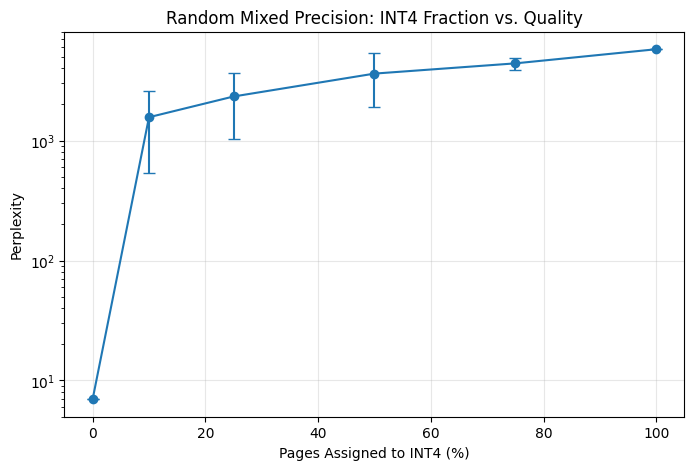

In [8]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))

plt.errorbar(
    100 * random_summary_df[
        "Requested_INT4_Fraction"
    ],
    random_summary_df[
        "Mean_PPL"
    ],
    yerr=random_summary_df[
        "Std_PPL"
    ],
    marker="o",
    capsize=4
)

plt.xlabel("Pages Assigned to INT4 (%)")
plt.ylabel("Perplexity")

plt.title(
    "Random Mixed Precision: "
    "INT4 Fraction vs. Quality"
)

plt.yscale("log")

plt.grid(alpha=0.3)

plt.show()

Random Mixed-Precision Baseline

Randomly assigning a subset of KV-cache pages to INT4 while keeping the remaining pages in INT8 caused severe quality degradation even at low INT4 fractions. With only 10% of pages in INT4, mean perplexity increased from 6.98 for uniform INT8 to approximately 1565, despite memory saving increasing only from 49.95% to 52.49%.

The large variation between random trials is also notable. At 10% INT4, perplexity ranged from approximately 436 to 3188, indicating that the identity of the pages selected for INT4 strongly influences model quality.

Therefore, the experiment provides two observations: uniform/random INT4 assignment is too aggressive with the current quantizer, and page selection matters substantially. This motivates evaluating structured page-selection policies rather than assigning low precision arbitrarily.

#5. Define and inspect the policies

In [9]:
# ============================================================
# CELL 5 — Fine-Grained Three-Precision Policy Setup
# ============================================================


# --------------------------------------------------
# Fine-grained INT4 sweep
#
# Previous experiments showed that 10% random INT4
# was already highly destructive, so we now focus
# on the low-INT4 region.
# --------------------------------------------------

SMALL_INT4_FRACTIONS = [
    0.00,
    0.01,
    0.025,
    0.05,
    0.075,
    0.10
]


# --------------------------------------------------
# FP16 protected-page configuration
# --------------------------------------------------

PROTECTED_FP16_FRACTION = 0.10

NUM_PROTECTED_FP16 = round(
    PROTECTED_FP16_FRACTION
    * NUM_PAGES
)

# Split protected pages between:
#   - beginning / prefix
#   - most recent context

NUM_PREFIX_FP16 = (
    NUM_PROTECTED_FP16 // 2
)

NUM_RECENT_FP16 = (
    NUM_PROTECTED_FP16
    - NUM_PREFIX_FP16
)


print("Total pages:", NUM_PAGES)

print(
    "Protected FP16 pages:",
    NUM_PROTECTED_FP16
)

print(
    "Prefix FP16 pages:",
    NUM_PREFIX_FP16
)

print(
    "Recent FP16 pages:",
    NUM_RECENT_FP16
)


# ============================================================
# Policy 1:
# Naive oldest-first
#
# Oldest pages -> INT4
# Everything else -> INT8
#
# No FP16 protection.
# ============================================================

def create_naive_recency_policy(
    int4_fraction
):

    num_int4 = round(
        int4_fraction
        * NUM_PAGES
    )

    policy = [
        "INT8"
    ] * NUM_PAGES


    # Oldest pages are at the beginning
    for page_idx in range(num_int4):

        policy[
            page_idx
        ] = "INT4"


    return policy


# ============================================================
# Policy 2:
# Three-tier protected policy
#
# Beginning      -> FP16
# Recent pages   -> FP16
# Oldest remaining pages -> INT4
# Everything else -> INT8
# ============================================================

def create_protected_three_tier_policy(
    int4_fraction
):

    policy = [
        "INT8"
    ] * NUM_PAGES


    # --------------------------------------------------
    # 1. Protect the prefix in FP16
    # --------------------------------------------------

    prefix_indices = list(
        range(
            NUM_PREFIX_FP16
        )
    )


    for page_idx in prefix_indices:

        policy[
            page_idx
        ] = "FP16"


    # --------------------------------------------------
    # 2. Protect the most recent pages in FP16
    # --------------------------------------------------

    recent_start = (
        NUM_PAGES
        - NUM_RECENT_FP16
    )

    recent_indices = list(
        range(
            recent_start,
            NUM_PAGES
        )
    )


    for page_idx in recent_indices:

        policy[
            page_idx
        ] = "FP16"


    # --------------------------------------------------
    # 3. INT4 budget
    #
    # Number is defined as a fraction of TOTAL pages,
    # but INT4 may only be assigned to unprotected pages.
    # --------------------------------------------------

    num_int4 = round(
        int4_fraction
        * NUM_PAGES
    )


    # Candidate pages are ordered oldest -> newest,
    # excluding protected FP16 pages.
    candidate_pages = [
        page_idx
        for page_idx in range(NUM_PAGES)
        if policy[page_idx] == "INT8"
    ]


    if num_int4 > len(candidate_pages):

        raise ValueError(
            "INT4 budget exceeds number of "
            "unprotected pages."
        )


    # Oldest unprotected pages receive INT4
    int4_indices = (
        candidate_pages[
            :num_int4
        ]
    )


    for page_idx in int4_indices:

        policy[
            page_idx
        ] = "INT4"


    return policy


# ============================================================
# Helper: summarize one policy without running the model
# ============================================================

def summarize_policy(
    policy,
    policy_name,
    requested_int4_fraction
):

    fp16_count = policy.count(
        "FP16"
    )

    int8_count = policy.count(
        "INT8"
    )

    int4_count = policy.count(
        "INT4"
    )


    memory_bytes = 0


    for page_idx, precision in enumerate(
        policy
    ):

        start = (
            page_idx
            * PAGE_SIZE
        )

        end = min(
            start + PAGE_SIZE,
            EVAL_TOKENS
        )

        memory_bytes += (
            logical_page_memory_bytes(
                end - start,
                precision
            )
        )


    fp16_memory_bytes = (
        NUM_PAGES
        * page_memory_bytes(
            "FP16"
        )
    )


    memory_saving = (
        100
        * (
            1
            - memory_bytes
            / fp16_memory_bytes
        )
    )


    return {
        "Policy":
            policy_name,

        "Requested_INT4_%":
            100
            * requested_int4_fraction,

        "FP16_Pages":
            fp16_count,

        "INT8_Pages":
            int8_count,

        "INT4_Pages":
            int4_count,

        "KV_Memory_MiB":
            memory_bytes
            / 1024**2,

        "Memory_Saving_%":
            memory_saving
    }


# ============================================================
# Build policy table
# ============================================================

policy_rows = []


for fraction in SMALL_INT4_FRACTIONS:

    naive_policy = (
        create_naive_recency_policy(
            fraction
        )
    )

    protected_policy = (
        create_protected_three_tier_policy(
            fraction
        )
    )


    policy_rows.append(
        summarize_policy(
            naive_policy,
            "Naive oldest-first",
            fraction
        )
    )


    policy_rows.append(
        summarize_policy(
            protected_policy,
            "Protected three-tier",
            fraction
        )
    )


policy_design_df = pd.DataFrame(
    policy_rows
)


display(policy_design_df)

Total pages: 128
Protected FP16 pages: 13
Prefix FP16 pages: 6
Recent FP16 pages: 7


,Policy,Requested_INT4_%,FP16_Pages,INT8_Pages,INT4_Pages,KV_Memory_MiB,Memory_Saving_%
0,Naive oldest-first,0.0,0,128,0,28.027344,49.951172
1,Protected three-tier,0.0,13,115,0,30.868317,44.878006
2,Naive oldest-first,1.0,0,127,1,27.917969,50.146484
3,Protected three-tier,1.0,13,114,1,30.758942,45.073318
4,Naive oldest-first,2.5,0,125,3,27.699219,50.537109
5,Protected three-tier,2.5,13,112,3,30.540192,45.463943
6,Naive oldest-first,5.0,0,122,6,27.371094,51.123047
7,Protected three-tier,5.0,13,109,6,30.212067,46.049881
8,Naive oldest-first,7.5,0,118,10,26.933594,51.904297
9,Protected three-tier,7.5,13,105,10,29.774567,46.831131


In [10]:
# ============================================================
# Inspect the proposed 5% INT4 three-tier policy
# ============================================================

example_policy = (
    create_protected_three_tier_policy(
        0.05
    )
)


print("\n5% INT4 Protected Three-Tier Example")
print("------------------------------------")

print(
    "FP16 pages:",
    [
        i
        for i, p in enumerate(
            example_policy
        )
        if p == "FP16"
    ]
)

print(
    "\nINT4 pages:",
    [
        i
        for i, p in enumerate(
            example_policy
        )
        if p == "INT4"
    ]
)

print(
    "\nINT8 pages:",
    example_policy.count(
        "INT8"
    )
)


5% INT4 Protected Three-Tier Example
------------------------------------
FP16 pages: [0, 1, 2, 3, 4, 5, 121, 122, 123, 124, 125, 126, 127]

INT4 pages: [6, 7, 8, 9, 10, 11]

INT8 pages: 109


Fine-Grained Three-Precision Policy Design

Because previous experiments showed severe degradation even when 10% of pages were randomly assigned to INT4, subsequent experiments focus on the low-INT4 regime: 0%,1%,2.5%,5%,7.5%,10%.

A three-tier policy is also introduced using FP16, INT8, and INT4. Approximately 10% of the cache pages are protected in FP16, divided between the beginning of the sequence and the most recent context. INT4 is applied only to the oldest remaining unprotected pages, while all other pages use INT8.

For the 5% INT4 configuration, the 128 pages are assigned as:

13 FP16+109 INT8+6 INT4.

The protected policy uses more memory than an INT8/INT4-only policy because FP16 pages are deliberately retained for potentially sensitive context. Therefore, policies must ultimately be compared using both model quality and KV-cache memory, rather than perplexity alone.

#6. Fine-grained naive recency sweep

In [11]:
# ============================================================
# CELL 6 — Fine-Grained Naive Recency Sweep
# ============================================================

naive_fine_results = []


for fraction in SMALL_INT4_FRACTIONS:

    policy = create_naive_recency_policy(
        fraction
    )

    int4_indices = [
        i
        for i, precision in enumerate(policy)
        if precision == "INT4"
    ]


    print("\n========================================")
    print(f"Requested INT4 fraction: {fraction:.1%}")
    print("========================================")

    print(
        "INT4 pages:",
        int4_indices
    )


    result = evaluate_mixed_precision(
        eval_ids,
        policy,
        show_progress=False
    )


    naive_fine_results.append({
        "Policy":
            "Naive oldest-first",

        "Requested_INT4_%":
            100 * fraction,

        "INT4_Pages":
            result["INT4_Pages"],

        "INT8_Pages":
            result["INT8_Pages"],

        "FP16_Pages":
            result["FP16_Pages"],

        "KV_Memory_MiB":
            result["KV_Memory_MiB"],

        "Memory_Saving_%":
            result["Memory_Saving_%"],

        "PPL":
            result["PPL"],

        "Delta_PPL_vs_INT8":
            result["PPL"]
            - endpoint_int8["PPL"],

        "PPL_Ratio_vs_INT8":
            result["PPL"]
            / endpoint_int8["PPL"]
    })


    print(
        f"Memory: "
        f"{result['KV_Memory_MiB']:.3f} MiB"
    )

    print(
        f"Memory saving: "
        f"{result['Memory_Saving_%']:.3f}%"
    )

    print(
        f"PPL: "
        f"{result['PPL']:.4f}"
    )


# ============================================================
# Results table
# ============================================================

naive_fine_df = pd.DataFrame(
    naive_fine_results
)


print("\nFine-Grained Naive Recency Results")
print("----------------------------------")

display(naive_fine_df)


Requested INT4 fraction: 0.0%
INT4 pages: []
Memory: 28.027 MiB
Memory saving: 49.951%
PPL: 6.9804

Requested INT4 fraction: 1.0%
INT4 pages: [0]
Memory: 27.918 MiB
Memory saving: 50.146%
PPL: 2456.3157

Requested INT4 fraction: 2.5%
INT4 pages: [0, 1, 2]
Memory: 27.699 MiB
Memory saving: 50.537%
PPL: 6403.6573

Requested INT4 fraction: 5.0%
INT4 pages: [0, 1, 2, 3, 4, 5]
Memory: 27.371 MiB
Memory saving: 51.123%
PPL: 3062.8920

Requested INT4 fraction: 7.5%
INT4 pages: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Memory: 26.934 MiB
Memory saving: 51.904%
PPL: 1881.8057

Requested INT4 fraction: 10.0%
INT4 pages: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Memory: 26.605 MiB
Memory saving: 52.490%
PPL: 2093.2810

Fine-Grained Naive Recency Results
----------------------------------


,Policy,Requested_INT4_%,INT4_Pages,INT8_Pages,FP16_Pages,KV_Memory_MiB,Memory_Saving_%,PPL,Delta_PPL_vs_INT8,PPL_Ratio_vs_INT8
0,Naive oldest-first,0.0,0,128,0,28.027344,49.951172,6.980423,0.000000,1.000000
1,Naive oldest-first,1.0,1,127,0,27.917969,50.146484,2456.315701,2449.335279,351.886372
2,Naive oldest-first,2.5,3,125,0,27.699219,50.537109,6403.657339,6396.676916,917.373832
3,Naive oldest-first,5.0,6,122,0,27.371094,51.123047,3062.891992,3055.911569,438.783154
4,Naive oldest-first,7.5,10,118,0,26.933594,51.904297,1881.805664,1874.825241,269.583331
5,Naive oldest-first,10.0,13,115,0,26.605469,52.490234,2093.280995,2086.300572,299.878820


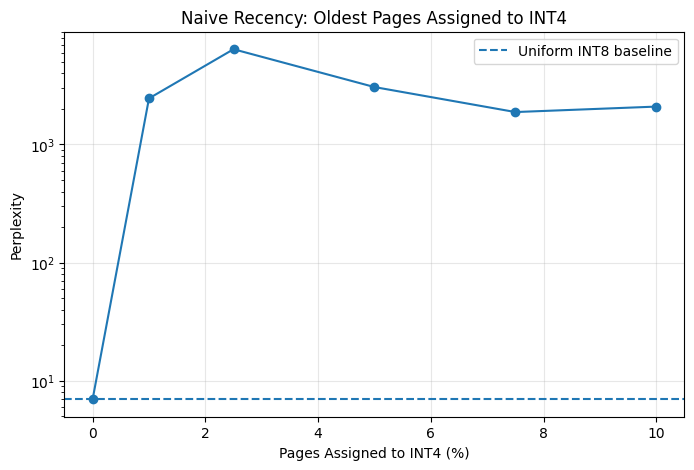

In [12]:
# ============================================================
# Plot: INT4 fraction vs quality
# ============================================================

import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))

plt.plot(
    naive_fine_df[
        "Requested_INT4_%"
    ],
    naive_fine_df[
        "PPL"
    ],
    marker="o"
)

plt.axhline(
    endpoint_int8["PPL"],
    linestyle="--",
    label="Uniform INT8 baseline"
)

plt.xlabel(
    "Pages Assigned to INT4 (%)"
)

plt.ylabel(
    "Perplexity"
)

plt.title(
    "Naive Recency: "
    "Oldest Pages Assigned to INT4"
)

plt.yscale("log")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

Naive Recency Policy

A fine-grained oldest-first policy was evaluated by assigning the oldest KV-cache pages to INT4 while keeping all remaining pages in INT8. The most important result occurs at the 1% INT4 setting, where only Page 0 (tokens 0–15) is quantized to INT4.

Despite changing only one of 128 pages, perplexity increased from the uniform INT8 baseline of 6.9804 to 2456.32, while memory saving improved only slightly from 49.95% to 50.15%. This indicates that aggressively quantizing the beginning of the sequence can severely damage model quality.

Perplexity is not monotonic as additional pages are assigned to INT4. Once the cache is heavily perturbed, further quantization can change attention behavior nonlinearly, so a larger number of INT4 pages does not necessarily produce a numerically larger perplexity. Nevertheless, every nonzero oldest-first configuration produced catastrophic degradation relative to the INT8 baseline.

These results provide empirical motivation for protecting the prefix rather than treating all old context as expendable.

#7. Protected Three-Tier Sweep

For every configuration:

first 6 pages → FP16

last 7 pages → FP16

selected old unprotected pages → INT4

everything else → INT8


In [13]:
# ============================================================
# CELL 7 — Protected Three-Tier Policy Sweep
# ============================================================

protected_results = []


for fraction in SMALL_INT4_FRACTIONS:

    policy = create_protected_three_tier_policy(
        fraction
    )


    fp16_indices = [
        i
        for i, precision in enumerate(policy)
        if precision == "FP16"
    ]

    int4_indices = [
        i
        for i, precision in enumerate(policy)
        if precision == "INT4"
    ]


    print("\n========================================")
    print(f"Requested INT4 fraction: {fraction:.1%}")
    print("========================================")

    print("FP16 pages:", fp16_indices)
    print("INT4 pages:", int4_indices)


    result = evaluate_mixed_precision(
        eval_ids,
        policy,
        show_progress=False
    )


    protected_results.append({
        "Policy":
            "Protected three-tier",

        "Requested_INT4_%":
            100 * fraction,

        "FP16_Pages":
            result["FP16_Pages"],

        "INT8_Pages":
            result["INT8_Pages"],

        "INT4_Pages":
            result["INT4_Pages"],

        "KV_Memory_MiB":
            result["KV_Memory_MiB"],

        "Memory_Saving_%":
            result["Memory_Saving_%"],

        "PPL":
            result["PPL"],

        "Delta_PPL_vs_FP16":
            result["PPL"]
            - endpoint_fp16["PPL"],

        "Delta_PPL_vs_INT8":
            result["PPL"]
            - endpoint_int8["PPL"],

        "PPL_Ratio_vs_INT8":
            result["PPL"]
            / endpoint_int8["PPL"]
    })


    print(
        f"Memory: "
        f"{result['KV_Memory_MiB']:.3f} MiB"
    )

    print(
        f"Memory saving: "
        f"{result['Memory_Saving_%']:.3f}%"
    )

    print(
        f"PPL: "
        f"{result['PPL']:.4f}"
    )


# ============================================================
# Results table
# ============================================================

protected_df = pd.DataFrame(
    protected_results
)


print("\nProtected Three-Tier Results")
print("----------------------------")

display(protected_df)


Requested INT4 fraction: 0.0%
FP16 pages: [0, 1, 2, 3, 4, 5, 121, 122, 123, 124, 125, 126, 127]
INT4 pages: []
Memory: 30.868 MiB
Memory saving: 44.878%
PPL: 6.9906

Requested INT4 fraction: 1.0%
FP16 pages: [0, 1, 2, 3, 4, 5, 121, 122, 123, 124, 125, 126, 127]
INT4 pages: [6]
Memory: 30.759 MiB
Memory saving: 45.073%
PPL: 14.4466

Requested INT4 fraction: 2.5%
FP16 pages: [0, 1, 2, 3, 4, 5, 121, 122, 123, 124, 125, 126, 127]
INT4 pages: [6, 7, 8]
Memory: 30.540 MiB
Memory saving: 45.464%
PPL: 137.5483

Requested INT4 fraction: 5.0%
FP16 pages: [0, 1, 2, 3, 4, 5, 121, 122, 123, 124, 125, 126, 127]
INT4 pages: [6, 7, 8, 9, 10, 11]
Memory: 30.212 MiB
Memory saving: 46.050%
PPL: 263.7236

Requested INT4 fraction: 7.5%
FP16 pages: [0, 1, 2, 3, 4, 5, 121, 122, 123, 124, 125, 126, 127]
INT4 pages: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Memory: 29.775 MiB
Memory saving: 46.831%
PPL: 774.0016

Requested INT4 fraction: 10.0%
FP16 pages: [0, 1, 2, 3, 4, 5, 121, 122, 123, 124, 125, 126, 127]
INT4 

,Policy,Requested_INT4_%,FP16_Pages,INT8_Pages,INT4_Pages,KV_Memory_MiB,Memory_Saving_%,PPL,Delta_PPL_vs_FP16,Delta_PPL_vs_INT8,PPL_Ratio_vs_INT8
0,Protected three-tier,0.0,13,115,0,30.868317,44.878006,6.990566,0.016922,0.010143,1.001453
1,Protected three-tier,1.0,13,114,1,30.758942,45.073318,14.446626,7.472983,7.466203,2.069592
2,Protected three-tier,2.5,13,112,3,30.540192,45.463943,137.548263,130.574620,130.567840,19.704861
3,Protected three-tier,5.0,13,109,6,30.212067,46.049881,263.723582,256.749939,256.743159,37.780459
4,Protected three-tier,7.5,13,105,10,29.774567,46.831131,774.001559,767.027916,767.021137,110.881757
5,Protected three-tier,10.0,13,102,13,29.446442,47.417068,1516.151640,1509.177997,1509.171217,217.200541


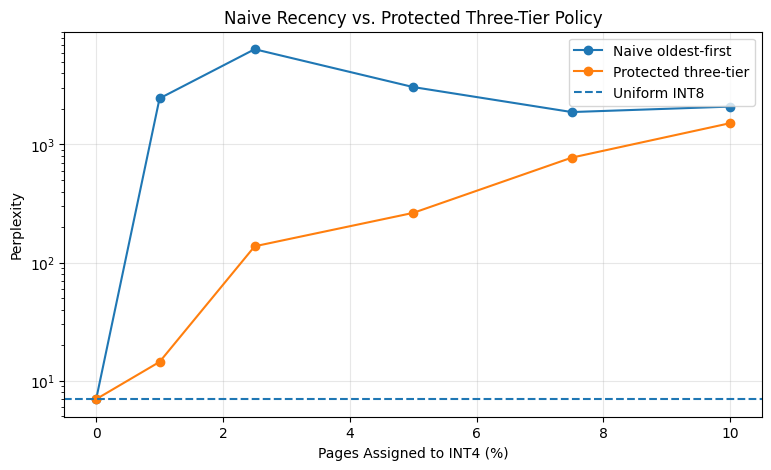

In [14]:
# ============================================================
# Compare naive vs protected policies
# ============================================================

import matplotlib.pyplot as plt


plt.figure(figsize=(9, 5))


plt.plot(
    naive_fine_df["Requested_INT4_%"],
    naive_fine_df["PPL"],
    marker="o",
    label="Naive oldest-first"
)


plt.plot(
    protected_df["Requested_INT4_%"],
    protected_df["PPL"],
    marker="o",
    label="Protected three-tier"
)


plt.axhline(
    endpoint_int8["PPL"],
    linestyle="--",
    label="Uniform INT8"
)


plt.xlabel(
    "Pages Assigned to INT4 (%)"
)

plt.ylabel(
    "Perplexity"
)

plt.title(
    "Naive Recency vs. Protected Three-Tier Policy"
)

plt.yscale("log")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Effect of Prefix Protection

Protecting the beginning of the sequence substantially improved mixed-precision performance. When only one page was assigned to INT4, the naive oldest-first policy compressed Page 0 and produced a perplexity of 2456.32. In contrast, the protected policy kept the first six pages in FP16 and assigned INT4 to Page 6, reducing perplexity to 14.45.

This demonstrates that page placement strongly affects quantization sensitivity and supports protecting the beginning of the sequence. However, the protected configuration is still substantially worse than uniform INT8 (PPL=6.98) while also using more memory. Therefore, page selection alone is not sufficient with the current INT4 implementation.

The next experiments focus on improving the INT4 quantization granularity before developing more sophisticated page-importance policies.

This also agrees with KVQuant: low-bit KV quantization benefits from much finer scaling than one scale over an entire page. KVQuant uses per-channel treatment for Keys and per-token treatment for Values, and explicitly discusses how outliers can distort the quantization range. It also reports benefits from retaining the initial token at FP16 at low bit widths, which is consistent with what we just observed experimentally.

#8. Compare better INT4 quantizers

In [15]:
# ============================================================
# CELL 8 — Compare INT4 Quantization Granularities
# ============================================================


# --------------------------------------------------
# Helper: compute quantization error
# --------------------------------------------------

def compute_quant_error(
    original,
    reconstructed
):
    diff = (
        original.float()
        - reconstructed.float()
    )

    mae = diff.abs().mean().item()

    rmse = torch.sqrt(
        (diff ** 2).mean()
    ).item()

    original_rms = torch.sqrt(
        (original.float() ** 2).mean()
    ).item()

    nrmse = (
        rmse / original_rms
        if original_rms > 0
        else 0.0
    )

    max_error = diff.abs().max().item()

    return {
        "MAE": mae,
        "RMSE": rmse,
        "NRMSE": nrmse,
        "Max_Error": max_error
    }


# ============================================================
# Scheme A — Current per-page quantization
#
# One scale for the entire [B,H,S,D] tensor.
# ============================================================

def quant_dequant_per_page(
    tensor,
    num_bits=4
):
    q, scale = symmetric_quantize(
        tensor,
        num_bits
    )

    dq = symmetric_dequantize(
        q,
        scale,
        dtype=tensor.dtype
    )

    num_scales = 1

    return dq, num_scales


# ============================================================
# Scheme B — Per-vector quantization
#
# One scale for every [batch, head, token] vector.
#
# Tensor:
#     [B, H, S, D]
#
# Scale:
#     [B, H, S, 1]
# ============================================================

def quant_dequant_per_vector(
    tensor,
    num_bits=4
):

    qmax = (
        2 ** (num_bits - 1)
    ) - 1

    qmin = -qmax

    x = tensor.float()


    # One scale per token vector
    max_abs = x.abs().amax(
        dim=-1,
        keepdim=True
    )

    scale = max_abs / qmax

    scale = torch.where(
        scale == 0,
        torch.ones_like(scale),
        scale
    )


    q = torch.round(
        x / scale
    )

    q = torch.clamp(
        q,
        qmin,
        qmax
    )


    dq = (
        q * scale
    ).to(tensor.dtype)


    num_scales = scale.numel()

    return dq, num_scales


# ============================================================
# Scheme C — K/V-aware quantization
#
# Keys:
#   one scale per channel/dimension across the page tokens
#   scale shape [B,H,1,D]
#
# Values:
#   one scale per token vector
#   scale shape [B,H,S,1]
#
# This is a page-local approximation inspired by the
# K/V-specific granularity used by KVQuant.
# ============================================================

def quant_dequant_key_per_channel(
    tensor,
    num_bits=4
):

    qmax = (
        2 ** (num_bits - 1)
    ) - 1

    qmin = -qmax

    x = tensor.float()


    # Reduce across sequence dimension S.
    #
    # [B,H,S,D]
    #       ↓
    # [B,H,1,D]
    max_abs = x.abs().amax(
        dim=2,
        keepdim=True
    )

    scale = max_abs / qmax

    scale = torch.where(
        scale == 0,
        torch.ones_like(scale),
        scale
    )


    q = torch.round(
        x / scale
    )

    q = torch.clamp(
        q,
        qmin,
        qmax
    )


    dq = (
        q * scale
    ).to(tensor.dtype)

    return dq, scale.numel()


def quant_dequant_value_per_token(
    tensor,
    num_bits=4
):
    # Same mathematical granularity as
    # the per-vector quantizer above.
    return quant_dequant_per_vector(
        tensor,
        num_bits
    )


# ============================================================
# Create a fresh FP16 cache for analysis
# ============================================================

with torch.inference_mode():

    analysis_outputs = model(
        input_ids=eval_ids,
        use_cache=True
    )


analysis_cache = (
    analysis_outputs.past_key_values
)


# --------------------------------------------------
# Analyze Page 6
#
# This is the first INT4 page used in our protected
# 1% experiment.
# --------------------------------------------------

TEST_PAGE = 6

page_start = (
    TEST_PAGE * PAGE_SIZE
)

page_end = (
    page_start + PAGE_SIZE
)


granularity_results = []


for layer_idx, layer in enumerate(
    analysis_cache.layers
):

    key_page = layer.keys[
        :, :, page_start:page_end, :
    ]

    value_page = layer.values[
        :, :, page_start:page_end, :
    ]


    # ==================================================
    # A — Per-page
    # ==================================================

    dq_k, k_scales = (
        quant_dequant_per_page(
            key_page,
            4
        )
    )

    dq_v, v_scales = (
        quant_dequant_per_page(
            value_page,
            4
        )
    )


    for tensor_name, original, dq, scales in [
        ("Key", key_page, dq_k, k_scales),
        ("Value", value_page, dq_v, v_scales)
    ]:

        metrics = compute_quant_error(
            original,
            dq
        )

        granularity_results.append({
            "Layer": layer_idx,
            "Tensor": tensor_name,
            "Scheme": "Per-page",
            "Scales": scales,
            **metrics
        })


    # ==================================================
    # B — Per-vector
    # ==================================================

    dq_k, k_scales = (
        quant_dequant_per_vector(
            key_page,
            4
        )
    )

    dq_v, v_scales = (
        quant_dequant_per_vector(
            value_page,
            4
        )
    )


    for tensor_name, original, dq, scales in [
        ("Key", key_page, dq_k, k_scales),
        ("Value", value_page, dq_v, v_scales)
    ]:

        metrics = compute_quant_error(
            original,
            dq
        )

        granularity_results.append({
            "Layer": layer_idx,
            "Tensor": tensor_name,
            "Scheme": "Per-vector",
            "Scales": scales,
            **metrics
        })


    # ==================================================
    # C — K/V-aware
    # ==================================================

    dq_k, k_scales = (
        quant_dequant_key_per_channel(
            key_page,
            4
        )
    )

    dq_v, v_scales = (
        quant_dequant_value_per_token(
            value_page,
            4
        )
    )


    for tensor_name, original, dq, scales in [
        ("Key", key_page, dq_k, k_scales),
        ("Value", value_page, dq_v, v_scales)
    ]:

        metrics = compute_quant_error(
            original,
            dq
        )

        granularity_results.append({
            "Layer": layer_idx,
            "Tensor": tensor_name,
            "Scheme": "K/V-aware",
            "Scales": scales,
            **metrics
        })


# ============================================================
# Results
# ============================================================

granularity_df = pd.DataFrame(
    granularity_results
)


granularity_summary_df = (
    granularity_df
    .groupby(
        ["Scheme", "Tensor"]
    )
    .agg(
        Mean_MAE=(
            "MAE",
            "mean"
        ),

        Mean_RMSE=(
            "RMSE",
            "mean"
        ),

        Mean_NRMSE=(
            "NRMSE",
            "mean"
        ),

        Worst_Error=(
            "Max_Error",
            "max"
        ),

        Scales_Per_Layer_Tensor=(
            "Scales",
            "first"
        )
    )
    .reset_index()
)


print(
    f"INT4 Granularity Comparison — Page {TEST_PAGE}"
)

print(
    "---------------------------------------"
)

display(
    granularity_summary_df
)

INT4 Granularity Comparison — Page 6
---------------------------------------


,Scheme,Tensor,Mean_MAE,Mean_RMSE,Mean_NRMSE,Worst_Error,Scales_Per_Layer_Tensor
0,K/V-aware,Key,0.096679,0.158095,0.060821,8.500000,256
1,K/V-aware,Value,0.116880,0.141204,0.163259,1.019531,32
2,Per-page,Key,0.629444,0.835983,0.276671,22.937500,1
3,Per-page,Value,0.190252,0.219995,0.254008,1.028320,1
4,Per-vector,Key,0.461679,0.637242,0.209344,22.625000,32
5,Per-vector,Value,0.116880,0.141204,0.163259,1.019531,32


In [16]:
# ============================================================
# Scale metadata cost for one logical 16-token page
# ============================================================

# FP32 scale = 4 bytes

# A: 1 K + 1 V scale per layer
per_page_scales = (
    NUM_LAYERS * 2
)


# B:
# 32 scales for K + 32 scales for V per layer
per_vector_scales = (
    NUM_LAYERS
    * (
        NUM_KV_HEADS * PAGE_SIZE
        + NUM_KV_HEADS * PAGE_SIZE
    )
)


# C:
#
# K:
#   H * D scales per layer
#
# V:
#   H * S scales per layer
kv_aware_scales = (
    NUM_LAYERS
    * (
        NUM_KV_HEADS * HEAD_DIM
        +
        NUM_KV_HEADS * PAGE_SIZE
    )
)


int4_payload_bytes = (
    ELEMENTS_PER_PAGE / 2
)


scale_memory_rows = []


for name, num_scales in [
    (
        "Per-page",
        per_page_scales
    ),
    (
        "Per-vector",
        per_vector_scales
    ),
    (
        "K/V-aware",
        kv_aware_scales
    )
]:

    metadata_bytes = (
        num_scales * 4
    )

    total_bytes = (
        int4_payload_bytes
        + metadata_bytes
    )

    saving = (
        100
        * (
            1
            - total_bytes
            / page_memory_bytes("FP16")
        )
    )


    scale_memory_rows.append({
        "Scheme": name,

        "Scales / Logical Page":
            num_scales,

        "Scale Metadata (KiB)":
            metadata_bytes / 1024,

        "INT4 Page Memory (KiB)":
            total_bytes / 1024,

        "Saving vs FP16 Page (%)":
            saving
    })


granularity_memory_df = pd.DataFrame(
    scale_memory_rows
)

print("\nMetadata / Memory Tradeoff")
print("--------------------------")

display(
    granularity_memory_df
)


Metadata / Memory Tradeoff
--------------------------


,Scheme,Scales / Logical Page,Scale Metadata (KiB),INT4 Page Memory (KiB),Saving vs FP16 Page (%)
0,Per-page,56,0.21875,112.21875,74.951172
1,Per-vector,1792,7.00000,119.00000,73.437500
2,K/V-aware,8064,31.50000,143.50000,67.968750


Per-Vector and K/V-Aware INT4 Quantization

Per-vector INT4 assigns an independent quantization scale to every token/head vector. For a page with shape [1,2,16,128], each of the 2×16=32 vectors of length 128 receives its own scale. This prevents large values in one token from determining the quantization range of unrelated tokens.

K/V-aware INT4 treats Keys and Values differently. Values use the same per-token vector scaling, while Keys use per-channel scaling: each Key dimension receives its own scale across the 16 tokens in the page. This results in 256 Key scales and 32 Value scales per layer.

Although K/V-aware quantization produced substantially lower Key reconstruction error, per-vector INT4 achieved better cache-aware perplexity (9.11 vs. 13.25). This shows that tensor reconstruction error alone is not a sufficient measure of model-level quantization quality. Based on perplexity, per-vector INT4 is selected as the current low-bit representation for subsequent experiments.

INT4 Quantization Granularity

The original INT4 baseline used one scale for an entire K or V page in each transformer layer. This produced large reconstruction error, particularly for Keys. To improve low-bit quantization, finer-grained scaling schemes were evaluated on Page 6.

For Keys, mean NRMSE decreased from 27.67% with per-page quantization to 20.93% with per-vector quantization, and further to only 6.08% with K/V-aware per-channel quantization. For Values, per-token quantization reduced mean NRMSE from 25.40% to 16.33%.

The improved accuracy requires additional scale metadata. A packed INT4 page requires approximately 112.22 KiB with per-page scaling, 119.00 KiB with per-vector scaling, and 143.50 KiB with the K/V-aware scheme. Even with the larger metadata overhead, the K/V-aware page still provides approximately 67.97% memory saving relative to FP16.

These results indicate that the failure of the earlier INT4 experiments was partly caused by overly coarse quantization granularity rather than bit width alone. The next experiment therefore evaluates whether the improved K/V-aware INT4 representation also preserves language-model perplexity, since lower tensor reconstruction error does not necessarily guarantee better model quality.

#9. Cache-aware comparison of INT4 quantizers

In [17]:
# ============================================================
# CELL 9 — Cache-Aware INT4 Granularity Comparison
# ============================================================


# --------------------------------------------------
# Compress a completed page using a chosen scheme
# --------------------------------------------------

@torch.inference_mode()
def quantize_completed_page_with_scheme(
    cache,
    start_token,
    end_token,
    precision,
    int4_scheme="per-page"
):
    """
    precision:
        FP16
        INT8
        INT4

    INT8:
        keeps our existing per-page quantizer.

    INT4 schemes:
        per-page
        per-vector
        kv-aware
    """

    # FP16 means no modification.
    if precision == "FP16":
        return


    for layer in cache.layers:

        key_page = layer.keys[
            :, :, start_token:end_token, :
        ]

        value_page = layer.values[
            :, :, start_token:end_token, :
        ]


        # ==================================================
        # INT8 — existing baseline quantizer
        # ==================================================

        if precision == "INT8":

            q_key, key_scale = symmetric_quantize(
                key_page,
                8
            )

            q_value, value_scale = symmetric_quantize(
                value_page,
                8
            )

            dq_key = symmetric_dequantize(
                q_key,
                key_scale,
                dtype=layer.keys.dtype
            )

            dq_value = symmetric_dequantize(
                q_value,
                value_scale,
                dtype=layer.values.dtype
            )


        # ==================================================
        # INT4
        # ==================================================

        elif precision == "INT4":

            if int4_scheme == "per-page":

                dq_key, _ = quant_dequant_per_page(
                    key_page,
                    4
                )

                dq_value, _ = quant_dequant_per_page(
                    value_page,
                    4
                )


            elif int4_scheme == "per-vector":

                dq_key, _ = quant_dequant_per_vector(
                    key_page,
                    4
                )

                dq_value, _ = quant_dequant_per_vector(
                    value_page,
                    4
                )


            elif int4_scheme == "kv-aware":

                dq_key, _ = (
                    quant_dequant_key_per_channel(
                        key_page,
                        4
                    )
                )

                dq_value, _ = (
                    quant_dequant_value_per_token(
                        value_page,
                        4
                    )
                )


            else:

                raise ValueError(
                    "Unknown INT4 scheme"
                )


        else:

            raise ValueError(
                f"Unknown precision: {precision}"
            )


        # --------------------------------------------------
        # Replace only this page
        # --------------------------------------------------

        layer.keys[
            :, :, start_token:end_token, :
        ] = dq_key

        layer.values[
            :, :, start_token:end_token, :
        ] = dq_value

In [18]:
# --------------------------------------------------
# Mixed-precision evaluator with selectable INT4 scheme
# --------------------------------------------------

def evaluate_mixed_precision_with_scheme(
    input_ids,
    page_precisions,
    int4_scheme
):

    seq_len = input_ids.shape[1]

    num_pages = math.ceil(
        seq_len / PAGE_SIZE
    )

    cache = DynamicCache(
        config=model.config
    )

    total_loss = 0.0
    total_targets = 0


    for page_idx in range(num_pages):

        start = (
            page_idx * PAGE_SIZE
        )

        end = min(
            start + PAGE_SIZE,
            seq_len
        )

        chunk_ids = input_ids[
            :, start:end
        ]


        cache_position = torch.arange(
            start,
            end,
            device=model.device
        )

        attention_mask = torch.ones(
            (input_ids.shape[0], end),
            dtype=torch.long,
            device=model.device
        )


        # --------------------------------------------------
        # Forward uses all previously compressed pages
        # --------------------------------------------------

        with torch.inference_mode():

            outputs = model(
                input_ids=chunk_ids,
                past_key_values=cache,
                attention_mask=attention_mask,
                cache_position=cache_position,
                use_cache=True
            )


        cache = outputs.past_key_values

        chunk_logits = outputs.logits


        # --------------------------------------------------
        # Global next-token loss
        # --------------------------------------------------

        num_valid_predictions = (
            min(end, seq_len - 1)
            - start
        )


        if num_valid_predictions > 0:

            logits_for_loss = chunk_logits[
                :, :num_valid_predictions, :
            ]

            targets = input_ids[
                :,
                start + 1:
                start + 1 + num_valid_predictions
            ]


            loss = F.cross_entropy(
                logits_for_loss.float().reshape(
                    -1,
                    logits_for_loss.shape[-1]
                ),
                targets.reshape(-1),
                reduction="sum"
            )


            total_loss += loss.item()

            total_targets += targets.numel()


        # --------------------------------------------------
        # Compress newly completed page
        # --------------------------------------------------

        precision = page_precisions[
            page_idx
        ]


        quantize_completed_page_with_scheme(
            cache,
            start,
            end,
            precision,
            int4_scheme=int4_scheme
        )


    nll = (
        total_loss
        / total_targets
    )

    ppl = math.exp(
        nll
    )


    return {
        "NLL": nll,
        "PPL": ppl,
        "Target_Tokens": total_targets,
        "Final_Cache_Length":
            cache.get_seq_length()
    }

In [19]:
# ============================================================
# Protected 1% policy
# ============================================================

test_policy = (
    create_protected_three_tier_policy(
        0.01
    )
)


print(
    "INT4 pages:",
    [
        i
        for i, p in enumerate(test_policy)
        if p == "INT4"
    ]
)


# ============================================================
# Run all three INT4 schemes
# ============================================================

scheme_results = []


for scheme in [
    "per-page",
    "per-vector",
    "kv-aware"
]:

    print(
        f"\nEvaluating INT4 scheme: {scheme}"
    )


    result = (
        evaluate_mixed_precision_with_scheme(
            eval_ids,
            test_policy,
            int4_scheme=scheme
        )
    )


    scheme_results.append({
        "INT4_Scheme": scheme,

        "PPL":
            result["PPL"],

        "NLL":
            result["NLL"],

        "Delta_PPL_vs_INT8":
            result["PPL"]
            - endpoint_int8["PPL"],

        "PPL_Ratio_vs_INT8":
            result["PPL"]
            / endpoint_int8["PPL"]
    })


scheme_ppl_df = pd.DataFrame(
    scheme_results
)


print(
    "\nCache-Aware INT4 Granularity Comparison"
)

print(
    "---------------------------------------"
)

display(
    scheme_ppl_df
)

INT4 pages: [6]

Evaluating INT4 scheme: per-page

Evaluating INT4 scheme: per-vector

Evaluating INT4 scheme: kv-aware

Cache-Aware INT4 Granularity Comparison
---------------------------------------


,INT4_Scheme,PPL,NLL,Delta_PPL_vs_INT8,PPL_Ratio_vs_INT8
0,per-page,14.446626,2.670461,7.466203,2.069592
1,per-vector,9.110066,2.209380,2.129643,1.305088
2,kv-aware,13.247869,2.583837,6.267446,1.897860


Cache-Aware Comparison of INT4 Granularity

The three INT4 quantization schemes were evaluated using the same protected three-tier configuration with only Page 6 assigned to INT4. Per-page INT4 produced a perplexity of 14.45, while per-vector quantization substantially improved perplexity to 9.11. The K/V-aware scheme achieved 13.25.

Interestingly, K/V-aware quantization produced the lowest Key reconstruction error but did not achieve the best perplexity. This demonstrates that numerical reconstruction error alone is not a sufficient proxy for language-model quality: different quantization errors can have very different effects on attention and subsequent predictions.

Per-vector INT4 currently provides the best measured quality among the tested 4-bit schemes while still reducing a logical page from 448 KiB in FP16 to approximately 119 KiB, a 73.44% per-page memory saving. It is therefore selected as the current INT4 representation for subsequent page-sensitivity experiments.

#10. Probe which pages tolerate INT4

In [20]:
# ============================================================
# CELL 10 — Single-Page INT4 Sensitivity Probe
# ============================================================


# --------------------------------------------------
# Protected baseline:
# prefix + recent pages FP16,
# all middle pages INT8
# --------------------------------------------------

protected_base_policy = (
    create_protected_three_tier_policy(
        0.00
    )
)


# Representative pages across the middle context
PROBE_PAGES = [
    6,
    10,
    20,
    40,
    60,
    80,
    100,
    120
]


# --------------------------------------------------
# Baseline quality
# --------------------------------------------------

baseline_result = (
    evaluate_mixed_precision_with_scheme(
        eval_ids,
        protected_base_policy,
        int4_scheme="per-vector"
    )
)

protected_baseline_ppl = (
    baseline_result["PPL"]
)


print(
    "Protected baseline PPL:",
    protected_baseline_ppl
)


# ============================================================
# Test exactly one INT4 page at a time
# ============================================================

probe_results = []


for page_idx in PROBE_PAGES:

    # Independent copy of baseline assignment
    policy = (
        protected_base_policy.copy()
    )

    # Change exactly one middle page
    # from INT8 -> INT4
    policy[page_idx] = "INT4"


    print(
        f"\nTesting Page {page_idx} "
        f"({page_idx * PAGE_SIZE}"
        f"–{page_idx * PAGE_SIZE + PAGE_SIZE - 1})"
    )


    result = (
        evaluate_mixed_precision_with_scheme(
            eval_ids,
            policy,
            int4_scheme="per-vector"
        )
    )


    ppl = result["PPL"]

    delta_ppl = (
        ppl
        - protected_baseline_ppl
    )

    relative_change = (
        100
        * (
            ppl
            / protected_baseline_ppl
            - 1
        )
    )


    probe_results.append({
        "Page":
            page_idx,

        "Start_Token":
            page_idx * PAGE_SIZE,

        "End_Token":
            page_idx * PAGE_SIZE
            + PAGE_SIZE - 1,

        "PPL":
            ppl,

        "Delta_PPL":
            delta_ppl,

        "Relative_PPL_Change_%":
            relative_change
    })


    print(
        f"PPL = {ppl:.4f}, "
        f"ΔPPL = {delta_ppl:.4f}"
    )


# ============================================================
# Results
# ============================================================

page_probe_df = pd.DataFrame(
    probe_results
)

print(
    "\nSingle-Page INT4 Sensitivity Probe"
)

print(
    "----------------------------------"
)

display(
    page_probe_df
)

Protected baseline PPL: 6.990565552646576

Testing Page 6 (96–111)
PPL = 9.1101, ΔPPL = 2.1195

Testing Page 10 (160–175)
PPL = 10.1720, ΔPPL = 3.1814

Testing Page 20 (320–335)
PPL = 7.8354, ΔPPL = 0.8449

Testing Page 40 (640–655)
PPL = 8.1329, ΔPPL = 1.1424

Testing Page 60 (960–975)
PPL = 8.9996, ΔPPL = 2.0090

Testing Page 80 (1280–1295)
PPL = 7.4385, ΔPPL = 0.4479

Testing Page 100 (1600–1615)
PPL = 7.1122, ΔPPL = 0.1216

Testing Page 120 (1920–1935)
PPL = 7.0096, ΔPPL = 0.0190

Single-Page INT4 Sensitivity Probe
----------------------------------


,Page,Start_Token,End_Token,PPL,Delta_PPL,Relative_PPL_Change_%
0,6,96,111,9.110066,2.119500,30.319439
1,10,160,175,10.172007,3.181441,45.510498
2,20,320,335,7.835441,0.844875,12.085933
3,40,640,655,8.132935,1.142369,16.341582
4,60,960,975,8.999569,2.009004,28.738789
5,80,1280,1295,7.438464,0.447898,6.407181
6,100,1600,1615,7.112184,0.121619,1.739755
7,120,1920,1935,7.009564,0.018998,0.271767


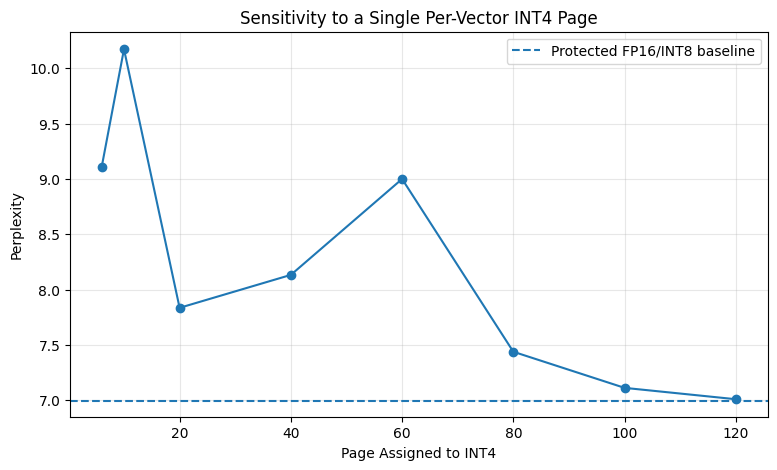

In [21]:
import matplotlib.pyplot as plt


plt.figure(figsize=(9, 5))


plt.plot(
    page_probe_df["Page"],
    page_probe_df["PPL"],
    marker="o"
)


plt.axhline(
    protected_baseline_ppl,
    linestyle="--",
    label="Protected FP16/INT8 baseline"
)


plt.xlabel(
    "Page Assigned to INT4"
)

plt.ylabel(
    "Perplexity"
)

plt.title(
    "Sensitivity to a Single Per-Vector INT4 Page"
)

plt.legend()

plt.grid(alpha=0.3)

plt.show()

Preliminary Single-Page Sensitivity Probe

Individual middle-context pages were independently changed from INT8 to per-vector INT4 while all other page assignments remained fixed. The resulting quality degradation varied substantially across page positions. For example, Page 10 increased perplexity by 3.18, whereas Page 100 increased it by only 0.12 and Page 120 by only 0.019.

These results confirm that different page assignments can have very different effects on model quality. However, the current experiment contains an important positional bias. A page can only influence predictions that occur after it has been compressed. Therefore, early pages are reused for many more future tokens than late pages. Page 6 can affect approximately 1,936 subsequent tokens in the 2048-token evaluation, while Page 120 can affect only approximately 112.

Consequently, the observed ΔPPL combines page sensitivity with exposure duration and should not yet be interpreted as an intrinsic page-importance score. A fair page-sensitivity comparison requires evaluating every candidate page over the same number of subsequent prediction tokens.

#11. Fixed-horizon page sensitivity

In [23]:
# ============================================================
# CELL 11 — Fixed-Horizon Single-Page Sensitivity
# ============================================================

SENSITIVITY_HORIZON = 128


# --------------------------------------------------
# Build cache up to and including a target page
#
# All completed pages use the protected baseline:
#   prefix -> FP16
#   middle -> INT8
#
# The target page is initially also built normally.
# --------------------------------------------------

def build_cache_through_page(
    input_ids,
    target_page
):

    cache = DynamicCache(
        config=model.config
    )

    for page_idx in range(
        target_page + 1
    ):

        start = (
            page_idx * PAGE_SIZE
        )

        end = (
            start + PAGE_SIZE
        )

        chunk_ids = input_ids[
            :, start:end
        ]


        cache_position = torch.arange(
            start,
            end,
            device=model.device
        )

        attention_mask = torch.ones(
            (input_ids.shape[0], end),
            dtype=torch.long,
            device=model.device
        )


        with torch.inference_mode():

            outputs = model(
                input_ids=chunk_ids,
                past_key_values=cache,
                attention_mask=attention_mask,
                cache_position=cache_position,
                use_cache=True
            )


        cache = outputs.past_key_values


        # ------------------------------------------
        # Apply baseline storage precision
        #
        # Prefix protected in FP16.
        # Other completed pages use INT8.
        #
        # IMPORTANT:
        # Do NOT quantize the target page yet.
        # We need the same source cache for both
        # baseline and INT4 branches.
        # ------------------------------------------

        if page_idx != target_page:

            baseline_precision = (
                "FP16"
                if page_idx < NUM_PREFIX_FP16
                else "INT8"
            )


            if baseline_precision == "INT8":

                quantize_completed_page_with_scheme(
                    cache,
                    start,
                    end,
                    "INT8",
                    int4_scheme="per-vector"
                )


    return cache


# --------------------------------------------------
# Clone DynamicCache
# --------------------------------------------------

def clone_dynamic_cache(
    source_cache
):

    new_cache = DynamicCache(
        config=model.config
    )


    for layer_idx, layer in enumerate(
        source_cache.layers
    ):

        new_cache.update(
            layer.keys.clone(),
            layer.values.clone(),
            layer_idx
        )


    return new_cache


# --------------------------------------------------
# Evaluate a fixed continuation from an existing cache
# --------------------------------------------------

def evaluate_continuation(
    cache,
    input_ids,
    start_token,
    num_tokens
):

    end_token = min(
        start_token + num_tokens,
        input_ids.shape[1]
    )

    total_loss = 0.0
    total_targets = 0


    # We process continuation in PAGE_SIZE chunks.
    for start in range(
        start_token,
        end_token,
        PAGE_SIZE
    ):

        end = min(
            start + PAGE_SIZE,
            end_token
        )


        chunk_ids = input_ids[
            :, start:end
        ]


        cache_position = torch.arange(
            start,
            end,
            device=model.device
        )


        attention_mask = torch.ones(
            (input_ids.shape[0], end),
            dtype=torch.long,
            device=model.device
        )


        with torch.inference_mode():

            outputs = model(
                input_ids=chunk_ids,
                past_key_values=cache,
                attention_mask=attention_mask,
                cache_position=cache_position,
                use_cache=True
            )


        cache = outputs.past_key_values

        logits = outputs.logits


        # ------------------------------------------
        # Score every continuation token.
        #
        # Logits from position t predict t+1,
        # so we need targets beginning at start+1.
        # ------------------------------------------

        valid_predictions = min(
            end - start,
            input_ids.shape[1] - start - 1
        )


        if valid_predictions > 0:

            logits_for_loss = logits[
                :, :valid_predictions, :
            ]

            targets = input_ids[
                :,
                start + 1:
                start + 1 + valid_predictions
            ]


            loss = F.cross_entropy(
                logits_for_loss.float().reshape(
                    -1,
                    logits_for_loss.shape[-1]
                ),
                targets.reshape(-1),
                reduction="sum"
            )


            total_loss += loss.item()
            total_targets += targets.numel()


        # Future continuation pages use INT8.
        quantize_completed_page_with_scheme(
            cache,
            start,
            end,
            "INT8",
            int4_scheme="per-vector"
        )


    nll = (
        total_loss / total_targets
    )


    return {
        "NLL": nll,
        "PPL": math.exp(nll),
        "Targets": total_targets
    }


# ============================================================
# Fixed-horizon sensitivity probe
# ============================================================

fixed_horizon_results = []


# We use more than the first 2048 tokens so even Page 120
# receives the full 128-token continuation.
sensitivity_ids = all_test_ids[
    :, :EVAL_TOKENS + SENSITIVITY_HORIZON + 1
].to(model.device)


for page_idx in PROBE_PAGES:

    print(
        f"\nTesting Page {page_idx}"
    )


    # End of selected page
    page_end = (
        (page_idx + 1)
        * PAGE_SIZE
    )


    # ----------------------------------------------
    # Build common cache state
    # ----------------------------------------------

    source_cache = (
        build_cache_through_page(
            sensitivity_ids,
            page_idx
        )
    )


    # ----------------------------------------------
    # Baseline branch:
    # selected page -> INT8
    # ----------------------------------------------

    baseline_cache = (
        clone_dynamic_cache(
            source_cache
        )
    )


    quantize_completed_page_with_scheme(
        baseline_cache,
        page_idx * PAGE_SIZE,
        page_end,
        "INT8",
        int4_scheme="per-vector"
    )


    baseline_quality = (
        evaluate_continuation(
            baseline_cache,
            sensitivity_ids,
            start_token=page_end,
            num_tokens=SENSITIVITY_HORIZON
        )
    )


    # ----------------------------------------------
    # INT4 branch:
    # exact same selected page -> per-vector INT4
    # ----------------------------------------------

    int4_cache = (
        clone_dynamic_cache(
            source_cache
        )
    )


    quantize_completed_page_with_scheme(
        int4_cache,
        page_idx * PAGE_SIZE,
        page_end,
        "INT4",
        int4_scheme="per-vector"
    )


    int4_quality = (
        evaluate_continuation(
            int4_cache,
            sensitivity_ids,
            start_token=page_end,
            num_tokens=SENSITIVITY_HORIZON
        )
    )


    # ----------------------------------------------
    # Sensitivity
    # ----------------------------------------------

    delta_nll = (
        int4_quality["NLL"]
        - baseline_quality["NLL"]
    )

    delta_ppl = (
        int4_quality["PPL"]
        - baseline_quality["PPL"]
    )


    fixed_horizon_results.append({
        "Page":
            page_idx,

        "Start_Token":
            page_idx * PAGE_SIZE,

        "End_Token":
            page_end - 1,

        "Horizon":
            SENSITIVITY_HORIZON,

        "Baseline_NLL":
            baseline_quality["NLL"],

        "INT4_NLL":
            int4_quality["NLL"],

        "Delta_NLL":
            delta_nll,

        "Baseline_PPL":
            baseline_quality["PPL"],

        "INT4_PPL":
            int4_quality["PPL"],

        "Delta_PPL":
            delta_ppl
    })


    print(
        f"Baseline NLL={baseline_quality['NLL']:.4f}, "
        f"INT4 NLL={int4_quality['NLL']:.4f}, "
        f"ΔNLL={delta_nll:.4f}"
    )


fixed_horizon_df = pd.DataFrame(
    fixed_horizon_results
)


print(
    "\nFixed-Horizon Page Sensitivity"
)

print(
    "------------------------------"
)

display(
    fixed_horizon_df
)


Testing Page 6
Baseline NLL=2.7723, INT4 NLL=3.0792, ΔNLL=0.3069

Testing Page 10
Baseline NLL=2.4139, INT4 NLL=2.9002, ΔNLL=0.4863

Testing Page 20
Baseline NLL=1.6303, INT4 NLL=1.7867, ΔNLL=0.1564

Testing Page 40
Baseline NLL=0.7441, INT4 NLL=0.8056, ΔNLL=0.0615

Testing Page 60
Baseline NLL=1.1615, INT4 NLL=1.6399, ΔNLL=0.4784

Testing Page 80
Baseline NLL=1.5121, INT4 NLL=1.7946, ΔNLL=0.2824

Testing Page 100
Baseline NLL=2.9560, INT4 NLL=3.0529, ΔNLL=0.0969

Testing Page 120
Baseline NLL=1.9965, INT4 NLL=2.0344, ΔNLL=0.0379

Fixed-Horizon Page Sensitivity
------------------------------


,Page,Start_Token,End_Token,Horizon,Baseline_NLL,INT4_NLL,Delta_NLL,Baseline_PPL,INT4_PPL,Delta_PPL
0,6,96,111,128,2.772321,3.079214,0.306892,15.995724,21.741296,5.745572
1,10,160,175,128,2.413859,2.900172,0.486313,11.177014,18.177279,7.000265
2,20,320,335,128,1.630288,1.786726,0.156438,5.105345,5.969875,0.864530
3,40,640,655,128,0.744105,0.805619,0.061514,2.104557,2.238082,0.133526
4,60,960,975,128,1.161521,1.639922,0.478401,3.194788,5.154767,1.959978
5,80,1280,1295,128,1.512138,1.794576,0.282438,4.536421,6.016923,1.480502
6,100,1600,1615,128,2.956048,3.052944,0.096896,19.221861,21.177609,1.955748
7,120,1920,1935,128,1.996539,2.034389,0.037850,7.363528,7.647580,0.284052


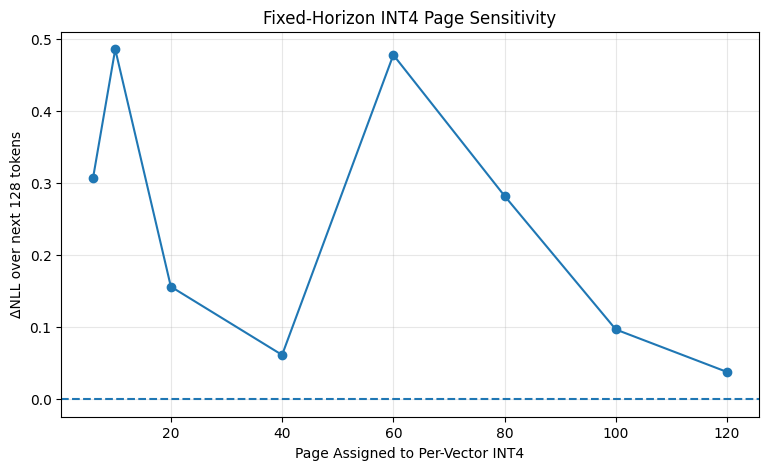

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(
    fixed_horizon_df["Page"],
    fixed_horizon_df["Delta_NLL"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Page Assigned to Per-Vector INT4"
)

plt.ylabel(
    "ΔNLL over next 128 tokens"
)

plt.title(
    "Fixed-Horizon INT4 Page Sensitivity"
)

plt.grid(alpha=0.3)

plt.show()

### Fixed-Horizon Page Sensitivity

To remove the positional bias of the initial sensitivity experiment, every candidate page was evaluated over the same 128-token future horizon. For each page, two identical cache states were created: one where the target page remained INT8 and one where only that page was changed to per-vector INT4. Sensitivity was defined as:

$$S(p) = \text{NLL}_{\text{INT4}, p} - \text{NLL}_{\text{INT8}, p}$$

The corrected experiment still revealed substantial variation between pages. For example, Pages 10 and 60 produced $\Delta\text{NLL}$ values of approximately 0.486 and 0.478, while Pages 40 and 120 produced only 0.062 and 0.038, respectively.

Therefore, page sensitivity cannot be explained solely by the amount of time a page remains in the cache. Different KV-cache pages genuinely respond differently to low-precision quantization under the same evaluation horizon. This supports the central motivation for an adaptive policy: INT4 should be assigned selectively rather than according to position alone.

The measured sensitivity is context-dependent and should be interpreted as sensitivity for the current model, text sequence, quantization method, and evaluation horizon rather than as a universal property of a page position.

#12. Full fixed-horizon sensitivity scan

In [25]:
# ============================================================
# CELL 12 — Full Fixed-Horizon Page Sensitivity Scan
# ============================================================

CANDIDATE_START_PAGE = NUM_PREFIX_FP16          # Page 6
CANDIDATE_END_PAGE = NUM_PAGES - NUM_RECENT_FP16 - 1  # Page 120

candidate_pages = list(
    range(
        CANDIDATE_START_PAGE,
        CANDIDATE_END_PAGE + 1
    )
)

print(
    "Candidate pages:",
    candidate_pages[0],
    "to",
    candidate_pages[-1]
)

print(
    "Number of candidate pages:",
    len(candidate_pages)
)


# --------------------------------------------------
# Need enough tokens for Page 120 + 128-token horizon
# --------------------------------------------------

scan_ids = all_test_ids[
    :,
    :EVAL_TOKENS + SENSITIVITY_HORIZON + 1
].to(model.device)


# --------------------------------------------------
# Master baseline cache
#
# We build it only once, sequentially.
# --------------------------------------------------

master_cache = DynamicCache(
    config=model.config
)

full_sensitivity_results = []


# ============================================================
# Process pages sequentially
# ============================================================

for page_idx in tqdm(
    range(CANDIDATE_END_PAGE + 1),
    desc="Full sensitivity scan"
):

    start = page_idx * PAGE_SIZE

    end = min(
        start + PAGE_SIZE,
        scan_ids.shape[1]
    )

    chunk_ids = scan_ids[
        :, start:end
    ]


    cache_position = torch.arange(
        start,
        end,
        device=model.device
    )

    attention_mask = torch.ones(
        (scan_ids.shape[0], end),
        dtype=torch.long,
        device=model.device
    )


    # --------------------------------------------------
    # Add the current page to the master cache
    # --------------------------------------------------

    with torch.inference_mode():

        outputs = model(
            input_ids=chunk_ids,
            past_key_values=master_cache,
            attention_mask=attention_mask,
            cache_position=cache_position,
            use_cache=True
        )


    master_cache = outputs.past_key_values


    # ==================================================
    # Candidate page sensitivity experiment
    # ==================================================

    if page_idx in candidate_pages:

        # ----------------------------------------------
        # Two identical branches
        # ----------------------------------------------

        baseline_cache = clone_dynamic_cache(
            master_cache
        )

        int4_cache = clone_dynamic_cache(
            master_cache
        )


        # ----------------------------------------------
        # Baseline branch:
        # target page -> INT8
        # ----------------------------------------------

        quantize_completed_page_with_scheme(
            baseline_cache,
            start,
            end,
            "INT8",
            int4_scheme="per-vector"
        )


        baseline_quality = evaluate_continuation(
            baseline_cache,
            scan_ids,
            start_token=end,
            num_tokens=SENSITIVITY_HORIZON
        )


        # ----------------------------------------------
        # Experimental branch:
        # target page -> per-vector INT4
        # ----------------------------------------------

        quantize_completed_page_with_scheme(
            int4_cache,
            start,
            end,
            "INT4",
            int4_scheme="per-vector"
        )


        int4_quality = evaluate_continuation(
            int4_cache,
            scan_ids,
            start_token=end,
            num_tokens=SENSITIVITY_HORIZON
        )


        # ----------------------------------------------
        # Sensitivity metrics
        # ----------------------------------------------

        delta_nll = (
            int4_quality["NLL"]
            - baseline_quality["NLL"]
        )

        relative_nll_change = (
            100
            * delta_nll
            / baseline_quality["NLL"]
            if baseline_quality["NLL"] != 0
            else 0.0
        )


        full_sensitivity_results.append({
            "Page":
                page_idx,

            "Start_Token":
                start,

            "End_Token":
                end - 1,

            "Horizon":
                SENSITIVITY_HORIZON,

            "Baseline_NLL":
                baseline_quality["NLL"],

            "INT4_NLL":
                int4_quality["NLL"],

            # Main sensitivity score
            "Delta_NLL":
                delta_nll,

            "Relative_NLL_Change_%":
                relative_nll_change,

            "Baseline_PPL":
                baseline_quality["PPL"],

            "INT4_PPL":
                int4_quality["PPL"],

            "Delta_PPL":
                int4_quality["PPL"]
                - baseline_quality["PPL"]
        })


        # Explicitly release branch caches
        del baseline_cache
        del int4_cache


    # ==================================================
    # Continue the MASTER baseline cache
    #
    # Prefix pages remain FP16.
    # Candidate pages become INT8 after their experiment.
    # ==================================================

    if page_idx >= NUM_PREFIX_FP16:

        quantize_completed_page_with_scheme(
            master_cache,
            start,
            end,
            "INT8",
            int4_scheme="per-vector"
        )


# ============================================================
# DataFrame
# ============================================================

full_sensitivity_df = pd.DataFrame(
    full_sensitivity_results
)


print("\nFull Page-Sensitivity Scan")
print("--------------------------")

print(
    "Pages evaluated:",
    len(full_sensitivity_df)
)

display(
    full_sensitivity_df.head()
)

Candidate pages: 6 to 120
Number of candidate pages: 115


Full sensitivity scan:   0%|          | 0/121 [00:00<?, ?it/s]


Full Page-Sensitivity Scan
--------------------------
Pages evaluated: 115


,Page,Start_Token,End_Token,Horizon,Baseline_NLL,INT4_NLL,Delta_NLL,Relative_NLL_Change_%,Baseline_PPL,INT4_PPL,Delta_PPL
0,6,96,111,128,2.772321,3.079214,0.306892,11.069858,15.995724,21.741296,5.745572
1,7,112,127,128,2.580672,2.736628,0.155956,6.043238,13.206004,15.434846,2.228842
2,8,128,143,128,2.630685,2.810173,0.179487,6.822836,13.883280,16.612785,2.729505
3,9,144,159,128,2.488634,3.041644,0.553010,22.221432,12.044810,20.939638,8.894828
4,10,160,175,128,2.413859,2.900172,0.486313,20.146701,11.177014,18.177279,7.000265


In [26]:
# ============================================================
# Most and least INT4-sensitive pages
# ============================================================

ranked_sensitivity_df = (
    full_sensitivity_df
    .sort_values(
        "Delta_NLL",
        ascending=False
    )
    .reset_index(drop=True)
)


print("Most sensitive pages")
print("--------------------")

display(
    ranked_sensitivity_df.head(10)
)


print("\nLeast sensitive pages")
print("---------------------")

display(
    ranked_sensitivity_df.tail(10)
)

Most sensitive pages
--------------------


,Page,Start_Token,End_Token,Horizon,Baseline_NLL,INT4_NLL,Delta_NLL,Relative_NLL_Change_%,Baseline_PPL,INT4_PPL,Delta_PPL
0,12,192,207,128,2.335480,4.018004,1.682524,72.041866,10.334422,55.590026,45.255604
1,52,832,847,128,1.824870,3.042582,1.217712,66.728694,6.201988,20.959286,14.757298
2,86,1376,1391,128,1.992297,2.839402,0.847106,42.519048,7.332355,17.105538,9.773183
3,58,928,943,128,1.375594,2.100745,0.725152,52.715548,3.957425,8.172257,4.214832
4,81,1296,1311,128,1.139685,1.834923,0.695237,61.002579,3.125785,6.264651,3.138866
5,47,752,767,128,1.970958,2.527607,0.556649,28.242557,7.177551,12.523505,5.345954
6,9,144,159,128,2.488634,3.041644,0.553010,22.221432,12.044810,20.939638,8.894828
7,87,1392,1407,128,2.001109,2.525828,0.524720,26.221461,7.397252,12.501248,5.103996
8,117,1872,1887,128,2.115457,2.639688,0.524231,24.780977,8.293373,14.008827,5.715454
9,44,704,719,128,1.676783,2.190490,0.513706,30.636424,5.348324,8.939590,3.591266



Least sensitive pages
---------------------


,Page,Start_Token,End_Token,Horizon,Baseline_NLL,INT4_NLL,Delta_NLL,Relative_NLL_Change_%,Baseline_PPL,INT4_PPL,Delta_PPL
105,53,848,863,128,1.947361,1.991454,0.044093,2.264253,7.010164,7.326180,0.316016
106,94,1504,1519,128,2.252613,2.293153,0.040540,1.799689,9.512555,9.906118,0.393563
107,114,1824,1839,128,1.990124,2.028689,0.038565,1.937814,7.316441,7.604110,0.287669
108,120,1920,1935,128,1.996539,2.034389,0.037850,1.895786,7.363528,7.647580,0.284052
109,118,1888,1903,128,2.157186,2.194004,0.036819,1.706790,8.646768,8.971064,0.324296
110,104,1664,1679,128,2.751529,2.779844,0.028315,1.029060,15.666575,16.116513,0.449937
111,39,624,639,128,0.541326,0.568082,0.026757,4.942825,1.718283,1.764879,0.046596
112,99,1584,1599,128,2.812609,2.837355,0.024747,0.879852,16.653305,17.070563,0.417258
113,41,656,671,128,1.154008,1.161304,0.007296,0.632227,3.170878,3.194097,0.023219
114,37,592,607,128,1.144222,1.139532,-0.004689,-0.409837,3.139997,3.125306,-0.014690


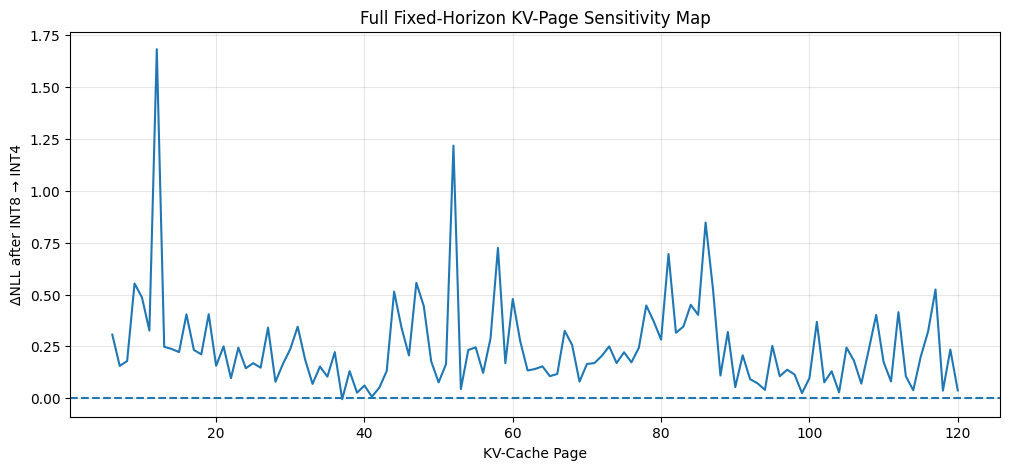

In [27]:
# ============================================================
# Sensitivity map
# ============================================================

import matplotlib.pyplot as plt


plt.figure(figsize=(12, 5))

plt.plot(
    full_sensitivity_df["Page"],
    full_sensitivity_df["Delta_NLL"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "KV-Cache Page"
)

plt.ylabel(
    "ΔNLL after INT8 → INT4"
)

plt.title(
    "Full Fixed-Horizon KV-Page Sensitivity Map"
)

plt.grid(alpha=0.3)

plt.show()

### Full Fixed-Horizon KV-Page Sensitivity Map

The fixed-horizon sensitivity experiment was extended to all 115 candidate pages between the protected prefix and recent-context regions. Each candidate page was independently evaluated by comparing an INT8 cache against an otherwise identical cache in which only the target page was demoted to per-vector INT4. Both branches were evaluated on the same 128 subsequent prediction positions.

Sensitivity was measured as:

$$S(p) = \text{NLL}_{\text{INT4}, p} - \text{NLL}_{\text{INT8}, p}$$

The resulting sensitivity map is highly non-uniform. Page 12 was the most sensitive observed page with $\Delta\text{NLL} \approx 1.683$, while several pages produced changes close to zero. The sensitive pages are distributed throughout the sequence rather than following a simple monotonic relationship with age or position.

This demonstrates that recency alone is insufficient for deciding KV-cache precision. Some relatively old pages tolerate INT4 well, while other pages at similar or later positions are highly sensitive.

A very small negative $\Delta\text{NLL}$ was observed for Page 37. This should be interpreted as approximately zero sensitivity rather than evidence that INT4 improves the model, since small quantization perturbations can occasionally reduce loss on a finite continuation.

The sensitivity map acts as an oracle analysis target, not a deployable policy: computing it requires evaluating both INT8 and INT4 alternatives using future ground-truth tokens. The next stage of the project will investigate whether inexpensive signals available during inference can predict this sensitivity.

#13. Oracle sensitivity-based policy

In [28]:
# ============================================================
# CELL 13 — Oracle Sensitivity-Based Mixed Precision
# ============================================================


# --------------------------------------------------
# Rank candidate pages from least sensitive to most sensitive
# --------------------------------------------------

least_sensitive_first = (
    full_sensitivity_df
    .sort_values(
        "Delta_NLL",
        ascending=True
    )
    ["Page"]
    .tolist()
)


print(
    "10 least-sensitive candidate pages:"
)

print(
    least_sensitive_first[:10]
)


# --------------------------------------------------
# INT4 page budgets
#
# Approximately correspond to:
# 1%, 2.5%, 5%, 7.5%, 10%
# of the full 128-page cache.
# --------------------------------------------------

ORACLE_INT4_BUDGETS = [
    1,
    3,
    6,
    10,
    13
]


# ============================================================
# Create oracle policy
# ============================================================

def create_oracle_policy(
    num_int4_pages
):
    """
    Protected FP16 prefix/recent pages remain unchanged.

    Among candidate middle pages, select the pages with
    the lowest measured fixed-horizon Delta_NLL for INT4.

    This is an oracle/analysis policy only.
    """

    # Begin from protected FP16/INT8 baseline
    policy = (
        protected_base_policy.copy()
    )


    selected_pages = (
        least_sensitive_first[
            :num_int4_pages
        ]
    )


    for page_idx in selected_pages:

        policy[
            page_idx
        ] = "INT4"


    return policy, selected_pages


# ============================================================
# Per-vector INT4 memory
# ============================================================

PER_VECTOR_INT4_PAGE_BYTES = (
    119.0 * 1024
)


def mixed_memory_with_per_vector_int4(
    policy
):

    total_bytes = 0


    for precision in policy:

        if precision == "FP16":

            total_bytes += (
                page_memory_bytes(
                    "FP16"
                )
            )


        elif precision == "INT8":

            total_bytes += (
                page_memory_bytes(
                    "INT8"
                )
            )


        elif precision == "INT4":

            total_bytes += (
                PER_VECTOR_INT4_PAGE_BYTES
            )


        else:

            raise ValueError(
                f"Unknown precision: {precision}"
            )


    fp16_total = (
        NUM_PAGES
        * page_memory_bytes(
            "FP16"
        )
    )


    saving = (
        100
        * (
            1
            - total_bytes
            / fp16_total
        )
    )


    return (
        total_bytes / 1024**2,
        saving
    )


# ============================================================
# Run oracle experiments
# ============================================================

oracle_results = []


for budget in ORACLE_INT4_BUDGETS:

    policy, selected_pages = (
        create_oracle_policy(
            budget
        )
    )


    print(
        "\n========================================"
    )

    print(
        f"Oracle INT4 pages: {budget}"
    )

    print(
        "Selected pages:",
        selected_pages
    )


    result = (
        evaluate_mixed_precision_with_scheme(
            eval_ids,
            policy,
            int4_scheme="per-vector"
        )
    )


    memory_mib, memory_saving = (
        mixed_memory_with_per_vector_int4(
            policy
        )
    )


    oracle_results.append({
        "INT4_Pages":
            budget,

        "INT4_Fraction_%":
            100
            * budget
            / NUM_PAGES,

        "Selected_Pages":
            selected_pages,

        "KV_Memory_MiB":
            memory_mib,

        "Memory_Saving_%":
            memory_saving,

        "PPL":
            result["PPL"],

        "Delta_PPL_vs_Protected_Baseline":
            result["PPL"]
            - protected_baseline_ppl,

        "PPL_Ratio_vs_Protected_Baseline":
            result["PPL"]
            / protected_baseline_ppl
    })


    print(
        f"PPL: {result['PPL']:.4f}"
    )

    print(
        f"Memory: {memory_mib:.3f} MiB"
    )


# ============================================================
# Table
# ============================================================

oracle_df = pd.DataFrame(
    oracle_results
)


print(
    "\nOracle Sensitivity-Based Policy"
)

print(
    "-------------------------------"
)

display(
    oracle_df
)

10 least-sensitive candidate pages:
[37, 41, 99, 39, 104, 118, 120, 114, 94, 53]

Oracle INT4 pages: 1
Selected pages: [37]
PPL: 7.5384
Memory: 30.766 MiB

Oracle INT4 pages: 3
Selected pages: [37, 41, 99]
PPL: 7.4981
Memory: 30.560 MiB

Oracle INT4 pages: 6
Selected pages: [37, 41, 99, 39, 104, 118]
PPL: 7.7797
Memory: 30.252 MiB

Oracle INT4 pages: 10
Selected pages: [37, 41, 99, 39, 104, 118, 120, 114, 94, 53]
PPL: 7.6116
Memory: 29.841 MiB

Oracle INT4 pages: 13
Selected pages: [37, 41, 99, 39, 104, 118, 120, 114, 94, 53, 42, 90, 40]
PPL: 7.9304
Memory: 29.533 MiB

Oracle Sensitivity-Based Policy
-------------------------------


,INT4_Pages,INT4_Fraction_%,Selected_Pages,KV_Memory_MiB,Memory_Saving_%,PPL,Delta_PPL_vs_Protected_Baseline,PPL_Ratio_vs_Protected_Baseline
0,1,0.78125,[37],30.765564,45.061493,7.538387,0.547821,1.078366
1,3,2.34375,"[37, 41, 99]",30.560059,45.428467,7.498085,0.507520,1.072601
2,6,4.68750,"[37, 41, 99, 39, 104, 118]",30.251801,45.978928,7.779684,0.789118,1.112883
3,10,7.81250,"[37, 41, 99, 39, 104, 118, 120, 114, 94, 53]",29.840790,46.712875,7.611557,0.620992,1.088833
4,13,10.15625,"[37, 41, 99, 39, 104, 118, 120, 114, 94, 53, 4...",29.532532,47.263336,7.930426,0.939860,1.134447


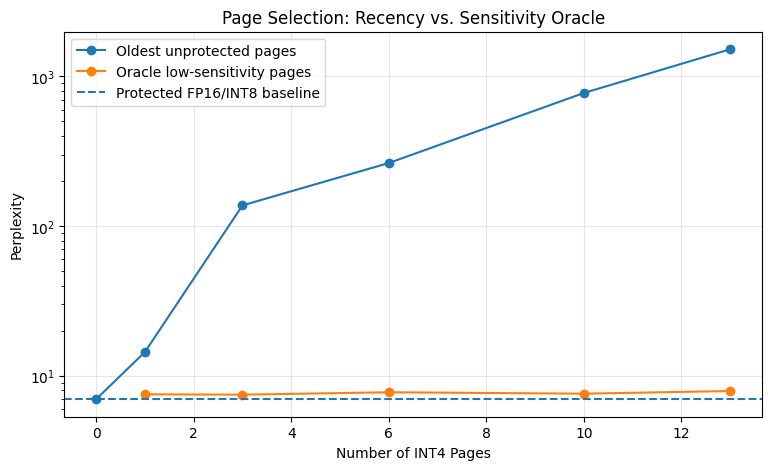

In [29]:
# ============================================================
# Oracle vs naive/protected selection
# ============================================================

import matplotlib.pyplot as plt


plt.figure(figsize=(9, 5))


# Protected old-page selection from Cell 7
plt.plot(
    protected_df[
        "INT4_Pages"
    ],
    protected_df[
        "PPL"
    ],
    marker="o",
    label="Oldest unprotected pages"
)


# Oracle low-sensitivity selection
plt.plot(
    oracle_df[
        "INT4_Pages"
    ],
    oracle_df[
        "PPL"
    ],
    marker="o",
    label="Oracle low-sensitivity pages"
)


plt.axhline(
    protected_baseline_ppl,
    linestyle="--",
    label="Protected FP16/INT8 baseline"
)


plt.xlabel(
    "Number of INT4 Pages"
)

plt.ylabel(
    "Perplexity"
)

plt.title(
    "Page Selection: Recency vs. Sensitivity Oracle"
)

plt.yscale(
    "log"
)

plt.legend()

plt.grid(alpha=0.3)

plt.show()

### Sensitivity-Oracle Page Selection

Pages were ranked according to their independently measured fixed-horizon INT4 sensitivity, $S(p) = \Delta\text{NLL}_p$, and the least-sensitive pages were selected for per-vector INT4. The protected prefix and recent-context regions remained in FP16, while all remaining pages used INT8.

Sensitivity-based selection dramatically outperformed oldest-first selection. For example, with 10 INT4 pages, the oldest-first protected policy produced a perplexity of approximately 774, whereas selecting the 10 least-sensitive pages produced a perplexity of only 7.61, close to the protected baseline of 6.99.

This provides strong evidence that which pages are quantized is substantially more important than page age alone. The result motivates an adaptive policy that attempts to predict page sensitivity using signals available during inference.

This method should be considered a sensitivity-oracle analysis baseline, not a deployable policy. It requires future ground-truth tokens to measure page sensitivity. In addition, pages are ranked according to their individual sensitivity, so the selected set is not guaranteed to be the globally optimal joint set because multiple quantized pages can interact nonlinearly.

#14. Memory-efficient sensitivity-oracle

### Revising the Mixed-Precision Architecture

The sensitivity-oracle experiment revealed an important issue with the FP16-protected three-tier policy. With 10 INT4 pages, the oracle achieved PPL = 7.61 using 29.84 MiB, while uniform INT8 achieved a better PPL = 6.98 using only 28.03 MiB.

Therefore, the problem is not the oracle page selection itself, but the additional memory spent keeping 13 pages permanently in FP16. Since uniform INT8 already performs almost identically to FP16:

$$\text{PPL}_{\text{FP16}} = 6.9736, \quad \text{PPL}_{\text{INT8}} = 6.9804$$

there is currently no evidence that a fixed 10% of pages must remain in FP16.

The revised design therefore uses INT8 as the default safe precision, while INT4 is applied only to carefully selected low-sensitivity pages. Important pages such as the prefix should primarily be protected from INT4, rather than automatically being stored in FP16.

The resulting hierarchy is:

* **INT4** $\leftarrow$ low-sensitivity pages
* **INT8** $\leftarrow$ default precision
* **FP16** $\leftarrow$ used only when experiments show that higher precision is necessary

This design provides a cleaner memory-quality tradeoff and avoids spending FP16 memory where INT8 is already sufficient.

In [30]:
# ============================================================
# CELL 14 — Memory-Efficient Sensitivity-Oracle Policy
# ============================================================


# --------------------------------------------------
# Create an INT8-default oracle policy
# --------------------------------------------------

def create_int8_oracle_policy(
    num_int4_pages
):
    """
    Default precision: INT8 everywhere.

    Only pages identified as least sensitive by the
    fixed-horizon oracle are demoted to per-vector INT4.

    Prefix/recent pages are therefore protected from INT4
    because they are not part of our candidate ranking.
    """

    policy = [
        "INT8"
    ] * NUM_PAGES


    selected_pages = (
        least_sensitive_first[
            :num_int4_pages
        ]
    )


    for page_idx in selected_pages:

        policy[
            page_idx
        ] = "INT4"


    return policy, selected_pages


# --------------------------------------------------
# Memory using:
#
# INT8     -> existing per-page INT8 storage
# INT4     -> per-vector INT4 storage (119 KiB/page)
# --------------------------------------------------

def int8_oracle_memory(
    policy
):

    total_bytes = 0


    for precision in policy:

        if precision == "INT8":

            total_bytes += (
                page_memory_bytes(
                    "INT8"
                )
            )


        elif precision == "INT4":

            total_bytes += (
                PER_VECTOR_INT4_PAGE_BYTES
            )


        else:

            raise ValueError(
                f"Unexpected precision: {precision}"
            )


    fp16_total = (
        NUM_PAGES
        * page_memory_bytes(
            "FP16"
        )
    )


    saving = (
        100
        * (
            1
            - total_bytes
            / fp16_total
        )
    )


    return (
        total_bytes / 1024**2,
        saving
    )


# ============================================================
# Evaluate oracle budgets
# ============================================================

int8_oracle_results = []


for budget in ORACLE_INT4_BUDGETS:

    policy, selected_pages = (
        create_int8_oracle_policy(
            budget
        )
    )


    print(
        "\n========================================"
    )

    print(
        f"INT8-default oracle — "
        f"{budget} INT4 pages"
    )

    print(
        "Selected pages:",
        selected_pages
    )


    result = (
        evaluate_mixed_precision_with_scheme(
            eval_ids,
            policy,
            int4_scheme="per-vector"
        )
    )


    memory_mib, memory_saving = (
        int8_oracle_memory(
            policy
        )
    )


    int8_oracle_results.append({
        "INT4_Pages":
            budget,

        "INT4_Fraction_%":
            100
            * budget
            / NUM_PAGES,

        "Selected_Pages":
            selected_pages,

        "KV_Memory_MiB":
            memory_mib,

        "Memory_Saving_%":
            memory_saving,

        "PPL":
            result["PPL"],

        "Delta_PPL_vs_INT8":
            result["PPL"]
            - endpoint_int8["PPL"],

        "PPL_Ratio_vs_INT8":
            result["PPL"]
            / endpoint_int8["PPL"]
    })


    print(
        f"PPL: "
        f"{result['PPL']:.4f}"
    )

    print(
        f"Memory: "
        f"{memory_mib:.3f} MiB"
    )

    print(
        f"Saving vs FP16: "
        f"{memory_saving:.3f}%"
    )


# ============================================================
# Results
# ============================================================

int8_oracle_df = pd.DataFrame(
    int8_oracle_results
)


print(
    "\nINT8-Default Sensitivity-Oracle"
)

print(
    "-------------------------------"
)

display(
    int8_oracle_df
)


INT8-default oracle — 1 INT4 pages
Selected pages: [37]
PPL: 7.5112
Memory: 27.925 MiB
Saving vs FP16: 50.135%

INT8-default oracle — 3 INT4 pages
Selected pages: [37, 41, 99]
PPL: 7.4638
Memory: 27.719 MiB
Saving vs FP16: 50.502%

INT8-default oracle — 6 INT4 pages
Selected pages: [37, 41, 99, 39, 104, 118]
PPL: 7.7483
Memory: 27.411 MiB
Saving vs FP16: 51.052%

INT8-default oracle — 10 INT4 pages
Selected pages: [37, 41, 99, 39, 104, 118, 120, 114, 94, 53]
PPL: 7.6044
Memory: 27.000 MiB
Saving vs FP16: 51.786%

INT8-default oracle — 13 INT4 pages
Selected pages: [37, 41, 99, 39, 104, 118, 120, 114, 94, 53, 42, 90, 40]
PPL: 7.9291
Memory: 26.692 MiB
Saving vs FP16: 52.337%

INT8-Default Sensitivity-Oracle
-------------------------------


,INT4_Pages,INT4_Fraction_%,Selected_Pages,KV_Memory_MiB,Memory_Saving_%,PPL,Delta_PPL_vs_INT8,PPL_Ratio_vs_INT8
0,1,0.78125,[37],27.924591,50.134659,7.511186,0.530763,1.076036
1,3,2.34375,"[37, 41, 99]",27.719086,50.501633,7.463770,0.483347,1.069243
2,6,4.68750,"[37, 41, 99, 39, 104, 118]",27.410828,51.052094,7.748330,0.767907,1.110009
3,10,7.81250,"[37, 41, 99, 39, 104, 118, 120, 114, 94, 53]",26.999817,51.786041,7.604367,0.623944,1.089385
4,13,10.15625,"[37, 41, 99, 39, 104, 118, 120, 114, 94, 53, 4...",26.691559,52.336502,7.929067,0.948644,1.135901


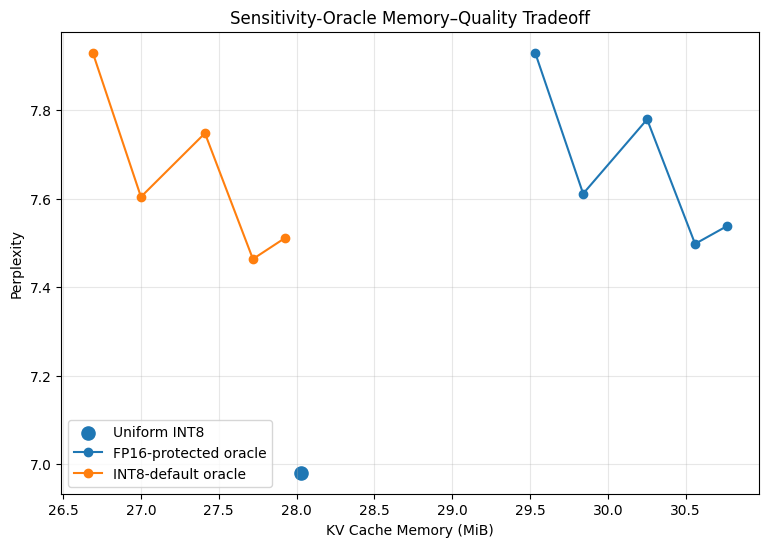

In [31]:
# ============================================================
# Memory-quality frontier
# ============================================================

import matplotlib.pyplot as plt


plt.figure(figsize=(9, 6))


# Uniform INT8
plt.scatter(
    endpoint_int8["KV_Memory_MiB"],
    endpoint_int8["PPL"],
    s=90,
    label="Uniform INT8"
)


# Protected FP16/INT8/INT4 oracle
plt.plot(
    oracle_df[
        "KV_Memory_MiB"
    ],
    oracle_df[
        "PPL"
    ],
    marker="o",
    label="FP16-protected oracle"
)


# INT8-default oracle
plt.plot(
    int8_oracle_df[
        "KV_Memory_MiB"
    ],
    int8_oracle_df[
        "PPL"
    ],
    marker="o",
    label="INT8-default oracle"
)


plt.xlabel(
    "KV Cache Memory (MiB)"
)

plt.ylabel(
    "Perplexity"
)

plt.title(
    "Sensitivity-Oracle Memory–Quality Tradeoff"
)

plt.legend()

plt.grid(alpha=0.3)

plt.show()

INT8-Default Sensitivity-Oracle Policy

The mixed-precision architecture was revised so that INT8 is the default cache precision, while only oracle-selected low-sensitivity pages are demoted to per-vector INT4. This removes the fixed FP16 reservation used in the previous three-tier policy.

The revised design achieves a genuine memory-quality tradeoff relative to uniform INT8. Uniform INT8 requires 28.03 MiB with PPL=6.98. Selecting 10 low-sensitivity pages for INT4 reduces cache memory to approximately 27.00 MiB while producing PPL=7.60. Thus, selective INT4 can reduce memory beyond the uniform INT8 baseline while retaining substantially better quality than recency-based INT4 assignment.

The INT8-default policy also dominates the previous fixed-FP16 design in memory usage, with no observed quality benefit from permanently reserving 10% of pages in FP16. FP16 should therefore be treated as an optional high-precision tier rather than a mandatory fixed allocation.

Results are not monotonic with the number of INT4 pages because the sensitivity ranking measures each page independently, while multiple quantized pages can interact through subsequent attention computations. Consequently, the sensitivity oracle is an analysis baseline rather than a globally optimal joint page-selection policy.

These results establish the objective for the adaptive policy: approximate the low-sensitivity page ranking using signals available during inference, while finding favorable points on the memory–quality Pareto frontier.

Memory–Quality Pareto Frontier

The Pareto frontier represents configurations for which memory usage cannot be reduced further without degrading model quality, and quality cannot be improved without using additional memory. A configuration is dominated if another configuration provides both lower memory usage and lower perplexity. Therefore, the goal of the adaptive KV-cache policy is not simply to minimize memory or perplexity independently, but to achieve the best possible tradeoff between the two.

#15. Save

In [32]:
# ============================================================
# CELL 15 — Save Notebook 05 Results
# ============================================================

import json


# --------------------------------------------------
# Save major experiment tables
# --------------------------------------------------

policy_design_df.to_csv(
    "mixed_precision_policy_design.csv",
    index=False
)

random_results_df.to_csv(
    "random_int4_trials.csv",
    index=False
)

random_summary_df.to_csv(
    "random_int4_summary.csv",
    index=False
)

naive_fine_df.to_csv(
    "naive_recency_fine_sweep.csv",
    index=False
)

protected_df.to_csv(
    "protected_three_tier_sweep.csv",
    index=False
)

granularity_summary_df.to_csv(
    "int4_granularity_error.csv",
    index=False
)

granularity_memory_df.to_csv(
    "int4_granularity_memory.csv",
    index=False
)

scheme_ppl_df.to_csv(
    "int4_granularity_ppl.csv",
    index=False
)

page_probe_df.to_csv(
    "preliminary_page_sensitivity.csv",
    index=False
)

fixed_horizon_df.to_csv(
    "fixed_horizon_probe.csv",
    index=False
)

full_sensitivity_df.to_csv(
    "full_page_sensitivity_map.csv",
    index=False
)

ranked_sensitivity_df.to_csv(
    "ranked_page_sensitivity.csv",
    index=False
)

oracle_df.to_csv(
    "fp16_protected_sensitivity_oracle.csv",
    index=False
)

int8_oracle_df.to_csv(
    "int8_default_sensitivity_oracle.csv",
    index=False
)


# --------------------------------------------------
# Compact notebook summary
# --------------------------------------------------

notebook05_summary = {

    "model":
        MODEL_ID,

    "evaluation_tokens":
        EVAL_TOKENS,

    "page_size":
        PAGE_SIZE,

    "num_pages":
        NUM_PAGES,

    "sensitivity_horizon":
        SENSITIVITY_HORIZON,

    "candidate_pages":
        len(full_sensitivity_df),

    # ----------------------------------------------
    # Baselines
    # ----------------------------------------------

    "uniform_int8_ppl":
        endpoint_int8["PPL"],

    "uniform_int8_memory_mib":
        endpoint_int8["KV_Memory_MiB"],

    # ----------------------------------------------
    # INT4 scheme selection
    # ----------------------------------------------

    "selected_int4_scheme":
        "per-vector",

    "per_vector_int4_page_memory_kib":
        119.0,

    "per_vector_int4_page_saving_vs_fp16_percent":
        73.4375,

    # ----------------------------------------------
    # Sensitivity map
    # ----------------------------------------------

    "most_sensitive_page":
        int(
            ranked_sensitivity_df.iloc[0]["Page"]
        ),

    "most_sensitive_delta_nll":
        float(
            ranked_sensitivity_df.iloc[0]["Delta_NLL"]
        ),

    "least_sensitive_page":
        int(
            ranked_sensitivity_df.iloc[-1]["Page"]
        ),

    "least_sensitive_delta_nll":
        float(
            ranked_sensitivity_df.iloc[-1]["Delta_NLL"]
        ),

    # ----------------------------------------------
    # Current oracle example
    # ----------------------------------------------

    "oracle_10_int4_pages":
        int(
            int8_oracle_df.loc[
                int8_oracle_df["INT4_Pages"] == 10,
                "INT4_Pages"
            ].iloc[0]
        ),

    "oracle_10_memory_mib":
        float(
            int8_oracle_df.loc[
                int8_oracle_df["INT4_Pages"] == 10,
                "KV_Memory_MiB"
            ].iloc[0]
        ),

    "oracle_10_ppl":
        float(
            int8_oracle_df.loc[
                int8_oracle_df["INT4_Pages"] == 10,
                "PPL"
            ].iloc[0]
        ),

    # ----------------------------------------------
    # Main conclusions
    # ----------------------------------------------

    "default_precision":
        "INT8",

    "main_finding":
        (
            "KV pages exhibit highly non-uniform "
            "INT4 sensitivity; sensitivity-based "
            "selection greatly outperforms recency."
        ),

    "next_stage":
        (
            "Predict page sensitivity using "
            "inference-time signals such as "
            "attention and recency."
        )
}


# --------------------------------------------------
# Save JSON
# --------------------------------------------------

with open(
    "notebook05_summary.json",
    "w"
) as f:

    json.dump(
        notebook05_summary,
        f,
        indent=4
    )


# --------------------------------------------------
# Print
# --------------------------------------------------

print("Notebook 05 Summary")
print("-------------------")

for key, value in notebook05_summary.items():
    print(f"{key}: {value}")


print("\nSaved:")
print("  mixed_precision_policy_design.csv")
print("  random_int4_trials.csv")
print("  random_int4_summary.csv")
print("  naive_recency_fine_sweep.csv")
print("  protected_three_tier_sweep.csv")
print("  int4_granularity_error.csv")
print("  int4_granularity_memory.csv")
print("  int4_granularity_ppl.csv")
print("  preliminary_page_sensitivity.csv")
print("  fixed_horizon_probe.csv")
print("  full_page_sensitivity_map.csv")
print("  ranked_page_sensitivity.csv")
print("  fp16_protected_sensitivity_oracle.csv")
print("  int8_default_sensitivity_oracle.csv")
print("  notebook05_summary.json")

Notebook 05 Summary
-------------------
model: Qwen/Qwen2.5-1.5B
evaluation_tokens: 2048
page_size: 16
num_pages: 128
sensitivity_horizon: 128
candidate_pages: 115
uniform_int8_ppl: 6.980422934522596
uniform_int8_memory_mib: 28.02734375
selected_int4_scheme: per-vector
per_vector_int4_page_memory_kib: 119.0
per_vector_int4_page_saving_vs_fp16_percent: 73.4375
most_sensitive_page: 12
most_sensitive_delta_nll: 1.6825235486030579
least_sensitive_page: 37
least_sensitive_delta_nll: -0.004689441528171301
oracle_10_int4_pages: 10
oracle_10_memory_mib: 26.99981689453125
oracle_10_ppl: 7.604367155411398
default_precision: INT8
main_finding: KV pages exhibit highly non-uniform INT4 sensitivity; sensitivity-based selection greatly outperforms recency.
next_stage: Predict page sensitivity using inference-time signals such as attention and recency.

Saved:
  mixed_precision_policy_design.csv
  random_int4_trials.csv
  random_int4_summary.csv
  naive_recency_fine_sweep.csv
  protected_three_tier_sw

### Key Findings Summary

The key story we've established is now quite clean:

$$\text{uniform INT4 fails}$$
$$\Downarrow$$
$$\text{better INT4 granularity helps}$$
$$\Downarrow$$
$$\text{pages have very different sensitivity}$$
$$\Downarrow$$
$$\text{recency is a poor selector}$$
$$\Downarrow$$
$$\text{sensitivity-based selection works dramatically better}$$
$$\Downarrow$$
$$\text{Now we need to predict sensitivity online}$$